# 02 – Outlier Detection (Data Exploration & Pre-Processing)

**Projekt:** Unsupervised Learning (Uni Münster, WS 26/27) – 3.839 transkribierte Bittbriefe an Papst Pius XII.
**Ziel dieses Notebooks:** Auffällige Briefe *vor* der Textrepräsentation und dem Clustering finden und einordnen.

**Methoden**

| Schritt | Methode | Quelle |
|---|---|---|
| 3 | Boxplot + IQR-Regel (visuell) | Vorlesung UL_05 |
| 4 | QQ-Plots, Skewness, log-Transformation (Normalitätscheck) | Vorlesung UL_05 |
| 5 | Univariater z-Score | Vorlesung UL_05 |
| 6 | Mahalanobis-Distanz + χ²-Plot (vs. euklidisch) | Vorlesung UL_05 |
| 7 | Robuste Mahalanobis-Distanz (MCD) | **Erweiterung, nicht Vorlesung** |
| 8 | Depth-based: Convex Hull Peeling | Vorlesung UL_05 |
| 9 | Angle-based: ABOD | Vorlesung UL_05 |
| 10 | Isolation Forest | **Erweiterung, nicht Vorlesung** |
| 11 | Local Outlier Factor (LOF) | **Erweiterung, nicht Vorlesung** |

**Bewusste Einschränkungen:** keine Dimensionsreduktion (PCA/t-SNE/UMAP), keine Embeddings, kein TF-IDF –
das folgt später im Projekt. Alle Methoden laufen auf handgebauten numerischen Features (Schritt 2).
`random_state = 42` überall.

In [1]:
import json
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from IPython.display import Markdown, display
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import outliers as O  # noqa: E402
from src.outliers import PALETTE, RANDOM_STATE, save_fig  # noqa: E402

DATA_ZIP = ROOT / "data" / "Habemus_Data_-20261108.zip"
RAW_DIR = ROOT / "data" / "raw"
FIG = ROOT / "figures" / "outliers"
RES = ROOT / "results" / "outliers"
FIG.mkdir(parents=True, exist_ok=True)
RES.mkdir(parents=True, exist_ok=True)

O.set_style()
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
STATS = {}   # sammelt alle Kennzahlen für results/outliers/outlier_stats.json
print("Projektordner:", ROOT)

Projektordner: C:\Users\Arne\uni_project\UL\new_results


## 1. Daten laden

**Was:** Zip entpacken, die drei CSVs (`documents_rawdata`, `documents_enriched`, `documents_summaries`) 1:1 über `id`
joinen, Listen-Spalten (`"['P123', 'P456']"`) per `ast.literal_eval` in echte Listen umwandeln.
Das Jahr wird per Regex `19[3-4]\d` aus `date_extracted_from_text` gezogen (Format meist `DD.MM.YYYY`, teils nur Jahr/Freitext).

**Sprache:** `main_language` fehlt bei ca. 20 % der Briefe. `langdetect` (Seed fest → deterministisch) wird für **alle**
Briefe ausgeführt (`lang_detected`). `language_filled` = `main_language`, Lücken mit `lang_detected` gefüllt.
Abweichungen zwischen beiden sind selbst ein Hinweis auf Datenprobleme (→ `lang_mismatch`, Schritt 2).

**Bezug zur Vorlesung:** Ausreißer können *Fehler* (Erfassung, Pipeline/ETL) oder *valide Extremwerte* sein (Folie „Causes of Outliers“).
Saubere Metadaten sind die Voraussetzung, um das später zu unterscheiden.

In [2]:
t0 = time.time()
df = O.load_data(DATA_ZIP, RAW_DIR)
df["year"] = df["date_extracted_from_text"].map(O.extract_year)
df["lang_detected"] = df["raw_text"].map(O.detect_language)
df["language_filled"] = df["main_language"].fillna(df["lang_detected"])
print(f"Geladen: {len(df)} Briefe, {df.shape[1]} Spalten ({time.time() - t0:.0f} s inkl. langdetect)")

overview = pd.DataFrame({
    "fehlend": [df["main_language"].isna().sum(), df["language_filled"].isna().sum(),
                df["date_extracted_from_text"].isna().sum(), df["year"].isna().sum()],
}, index=["main_language", "language_filled", "date_extracted_from_text", "year (Regex)"])
overview["Anteil %"] = (overview["fehlend"] / len(df) * 100).round(1)
display(overview)
display(df["language_filled"].value_counts().rename("Briefe").to_frame().T)

Geladen: 3839 Briefe, 40 Spalten (26 s inkl. langdetect)


,fehlend,Anteil %
main_language,761,19.8
language_filled,0,0.0
date_extracted_from_text,310,8.1
year (Regex),330,8.6


language_filled,Italienisch,Deutsch,Französisch,Englisch,Spanisch,Portugiesisch,Polnisch,Hebräisch,Rumänisch,Ungarisch,Latein,Katalanisch,Jiddisch,Kroatisch
Briefe,2139,1060,468,55,28,21,14,14,14,12,8,4,1,1


**Interpretation:** Der Join ist verlustfrei (3.839 Briefe in allen drei Dateien, `id` eindeutig). `main_language` fehlt bei
761 Briefen (19,8 %). Nach dem Auffüllen mit `langdetect` bleibt keine Sprache mehr leer. Bei 330 Briefen (8,6 %) lässt sich
kein Jahr 1930–1949 aus dem Datumsfeld extrahieren. Diese fehlen nur beim Feature `year` und gehen nicht in die
multivariaten Verfahren ein.

## 2. Feature-Tabelle pro Brief

**Was:** 13 numerische Features je Brief plus die Bool-Spalte `lang_mismatch`:

| Feature | Definition |
|---|---|
| `n_words`, `n_chars` | Wörter (Whitespace-Split), Zeichen von `raw_text` |
| `avg_word_len` | mittlere Wortlänge in Zeichen |
| `share_non_alpha` | Anteil Zeichen, die weder Buchstabe noch Leerzeichen sind (Satzzeichen, Ziffern, Symbole) |
| `share_digits` | Anteil Ziffern an allen Zeichen |
| `share_upper` | Anteil Großbuchstaben an allen Buchstaben |
| `n_persons`, `n_places`, `n_organisations` | Anzahl verknüpfter Personen-/Orts-/Organisations-IDs |
| `n_languages`, `n_attachments`, `n_cases` | Länge der Listen `languages`, `attachment_ids`, `cases` |
| `year` | Jahr aus `date_extracted_from_text` (NaN, wenn keins gefunden) |
| `lang_mismatch` | `lang_detected ≠ main_language`, nur wo beide vorhanden; Latein/Jiddisch ausgenommen (von `langdetect` nicht unterstützt) |

**Warum:** Länge, Zeichenzusammensetzung und Annotationsdichte erfassen genau die Fehlerarten aus der Vorlesung
(Erfassungsfehler, Pipeline-Fehler) und echte Sonderfälle (sehr lange, sehr personenreiche Briefe), ohne Textrepräsentationen vorwegzunehmen.

In [3]:
feat = O.build_features(df)
FEATURES = ["n_words", "n_chars", "avg_word_len", "share_non_alpha", "share_digits", "share_upper",
            "n_persons", "n_places", "n_organisations", "n_languages", "n_attachments", "n_cases", "year"]
# stetige bzw. quasi-stetige Features (für QQ-Plots, z-Score, multivariate Verfahren)
CONT = ["n_words", "n_chars", "avg_word_len", "share_non_alpha", "share_digits", "share_upper",
        "n_persons", "n_places", "n_organisations"]
feat.to_csv(RES / "features.csv", index=False)
# Sprachspalten für spätere Notebooks (Dimensionsreduktion), damit langdetect nicht erneut läuft
df[["id", "main_language", "lang_detected", "language_filled"]].to_csv(RES / "languages.csv", index=False)
print("lang_mismatch:", int(feat["lang_mismatch"].sum()), "Briefe")
display(feat[FEATURES].describe().T.round(3))

lang_mismatch: 137 Briefe


,count,mean,std,min,25%,50%,75%,max
n_words,3839.0,329.315,295.582,6.000,150.000,243.000,411.000,3531.000
n_chars,3839.0,2116.003,1898.071,37.000,961.500,1551.000,2642.000,20537.000
avg_word_len,3839.0,5.447,0.400,3.879,5.198,5.427,5.673,8.383
share_non_alpha,3839.0,0.045,0.019,0.000,0.034,0.042,0.053,0.339
share_digits,3839.0,0.015,0.012,0.000,0.008,0.012,0.019,0.196
share_upper,3839.0,0.079,0.073,0.000,0.050,0.064,0.086,1.000
n_persons,3839.0,3.308,2.759,0.000,2.000,2.000,4.000,42.000
n_places,3839.0,4.695,2.863,0.000,3.000,4.000,6.000,29.000
n_organisations,3839.0,0.694,0.908,0.000,0.000,1.000,1.000,10.000
n_languages,3839.0,0.326,0.588,0.000,0.000,0.000,1.000,3.000


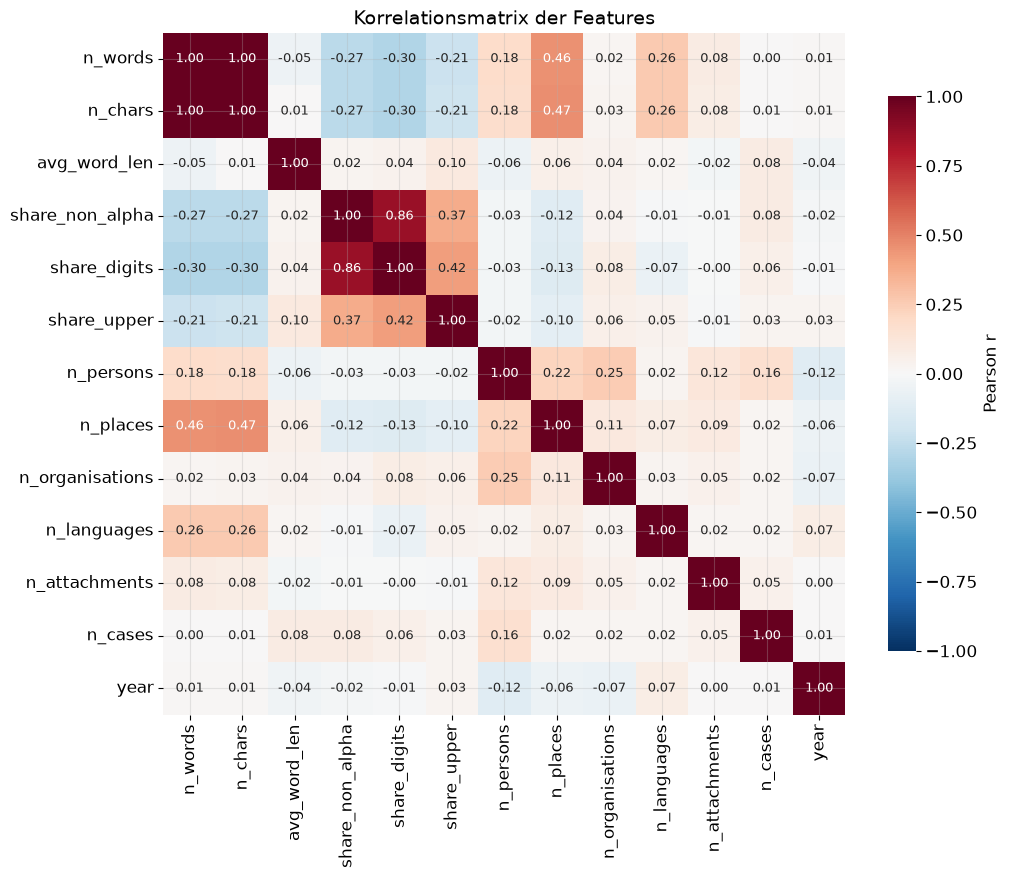

,,r
n_words,n_chars,0.997
share_non_alpha,share_digits,0.862
n_chars,n_places,0.466
n_words,n_places,0.459
share_digits,share_upper,0.419


In [4]:
corr = feat[FEATURES].corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=O.DIV_CMAP, vmin=-1, vmax=1, square=True,
            annot_kws={"size": 9}, cbar_kws={"label": "Pearson r", "shrink": 0.8}, ax=ax)
ax.set_title("Korrelationsmatrix der Features")
save_fig(fig, "correlation_heatmap", FIG)
plt.show()
top_pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
             .sort_values(key=np.abs, ascending=False).head(5).round(3))
display(top_pairs.rename("r").to_frame())

**Interpretation:** Die Verteilungen sind stark rechtsschief: Der Median liegt bei 243 Wörtern, das Maximum bei 3.531;
`share_upper` reicht bis 1,0 (reine Großschreibung). `n_words` und `n_chars` korrelieren mit r ≈ 0,997 und sind damit
praktisch redundant. Das ist für die Mahalanobis-Distanz in Schritt 6 wichtig, weil Σ sonst fast singulär wird.
Bei 137 Briefen weicht die erkannte Sprache von `main_language` ab.

## 3. Visuelle Methode: Boxplot + IQR-Regel  *[Vorlesung]*

**Was:** Boxplots je Feature. Punkte außerhalb von $[q_{0.25} - k\cdot IQR,\ q_{0.75} + k\cdot IQR]$ gelten als Ausreißer, mit $k = 1.5$
(Standard-Whisker) und zum Vergleich $k = 3.0$.

**Bezug zur Vorlesung:** Folie „Visual Outlier Detection“: Median und Quartile sind robust, aber *die Wahl des Faktors ist
hochgradig subjektiv*, und die visuelle Prüfung ist auf 1–2 Dimensionen beschränkt. Beides zeigen wir hier explizit.

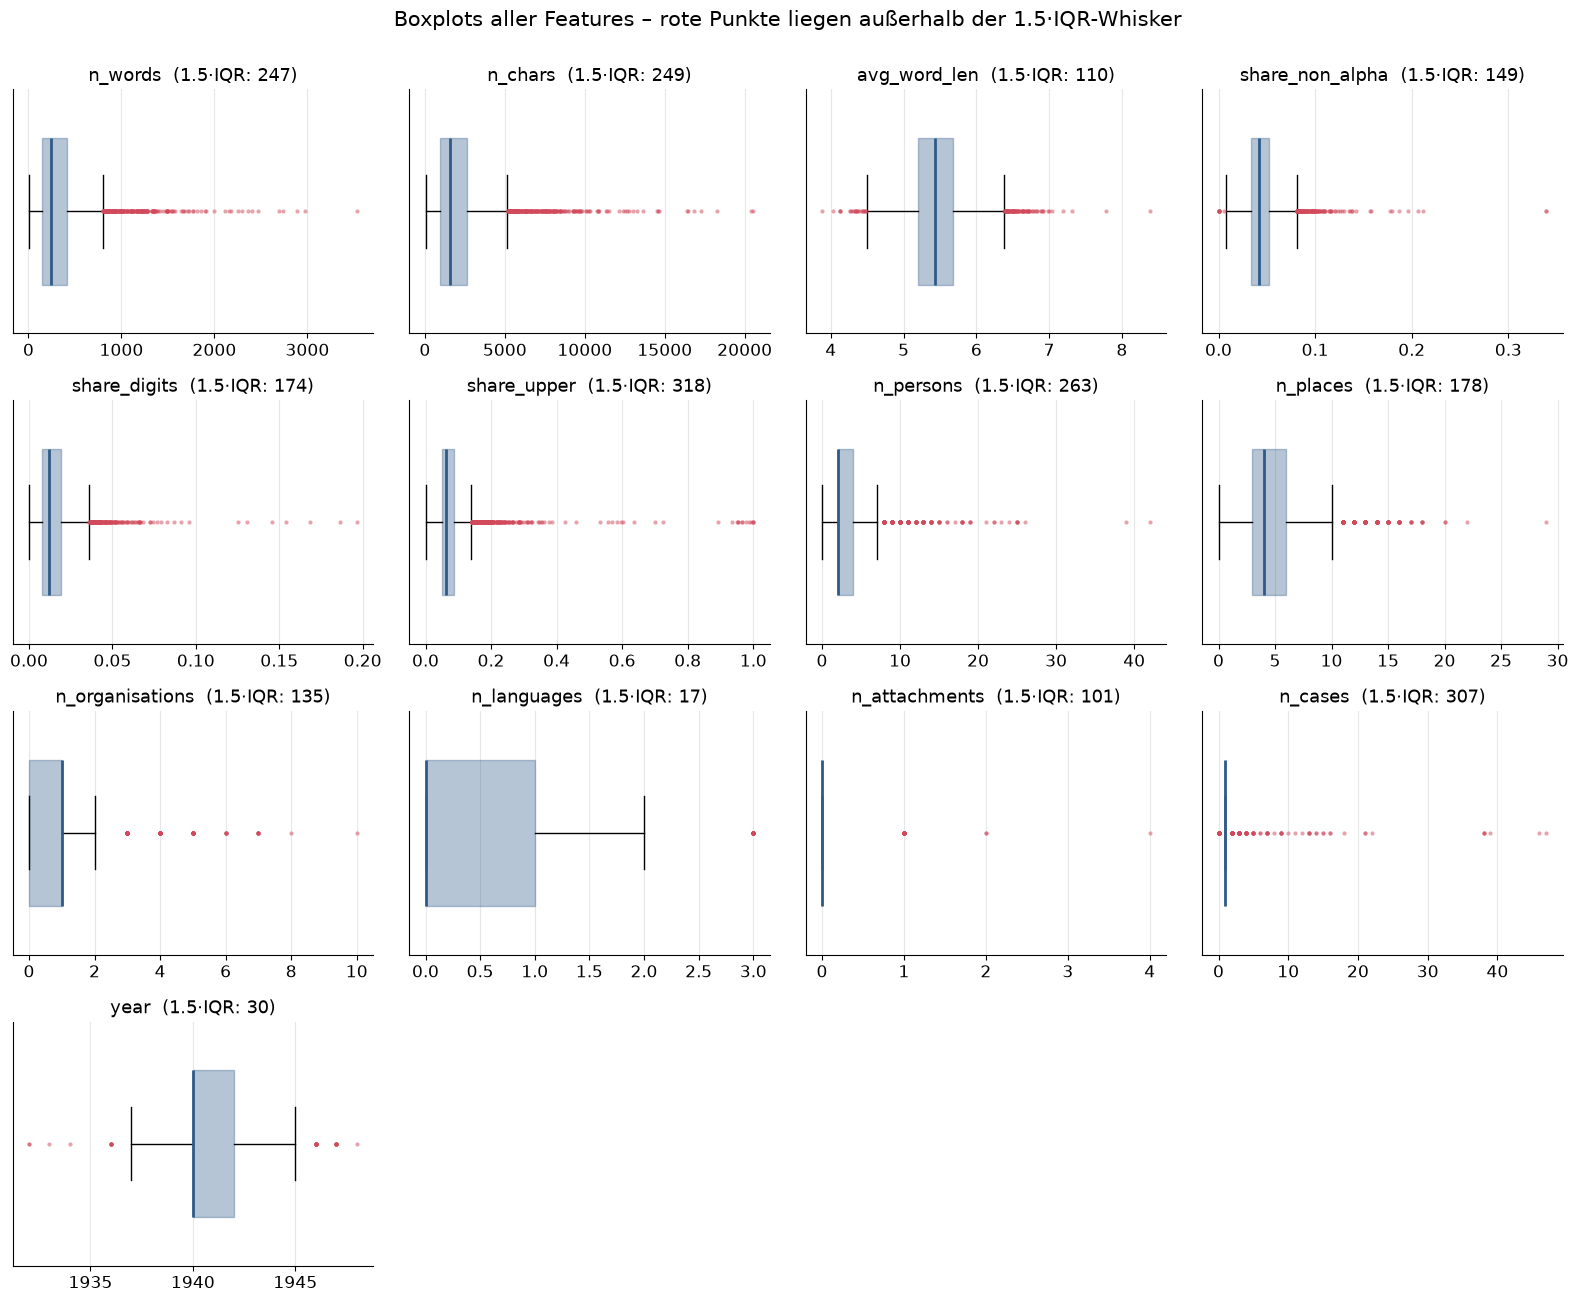

In [5]:
fig, axes = plt.subplots(4, 4, figsize=(16, 13))
for ax, c in zip(axes.flat, FEATURES):
    vals = feat[c].dropna()
    ax.boxplot(vals, orientation="horizontal", widths=0.6, patch_artist=True,
               boxprops=dict(facecolor=PALETTE["main"], alpha=0.35, color=PALETTE["main"]),
               medianprops=dict(color=PALETTE["main"], lw=2),
               flierprops=dict(marker="o", markersize=3, markerfacecolor=PALETTE["outlier"],
                               markeredgecolor="none", alpha=0.5))
    n_out = O.iqr_flags(feat, [c], 1.5)[c].sum()
    ax.set_title(f"{c}  (1.5·IQR: {n_out})", fontsize=13)
    ax.set_yticks([])
for ax in axes.flat[len(FEATURES):]:
    ax.remove()
fig.suptitle("Boxplots aller Features – rote Punkte liegen außerhalb der 1.5·IQR-Whisker", y=1.0)
fig.tight_layout()
save_fig(fig, "boxplots_features", FIG)
plt.show()

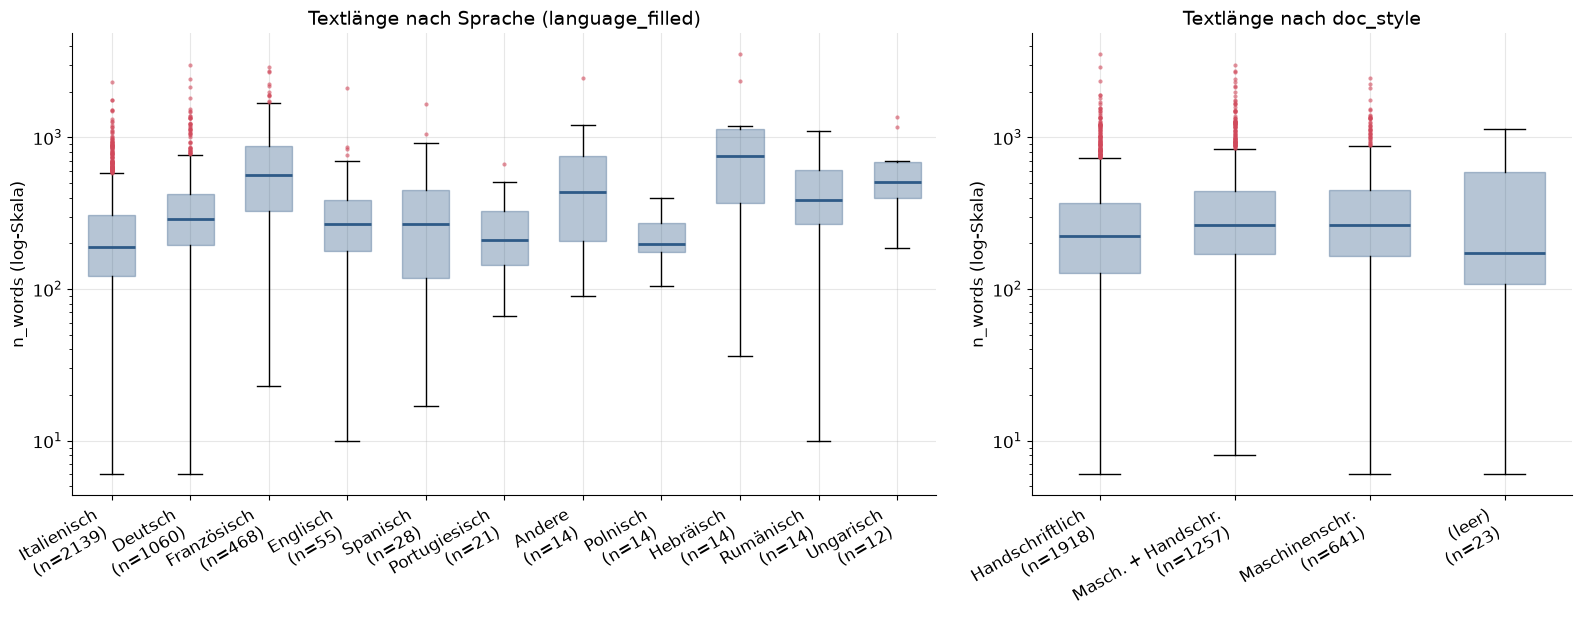

language_filled,Italienisch,Polnisch,Portugiesisch,Englisch,Spanisch,Deutsch,Rumänisch,Andere,Ungarisch,Französisch,Hebräisch
Median n_words,190.0,198.5,211.0,268.0,268.5,290.0,385.5,434.0,506.5,565.0,751.5


doc_style,(leer),Handschriftlich,Masch. + Handschr.,Maschinenschr.
Median n_words,172.0,223.0,262.0,263.0


In [6]:
# n_words nach Sprache und nach doc_style
lang_counts = df["language_filled"].value_counts()
top_langs = lang_counts[lang_counts >= 10].index
lang_grp = df["language_filled"].where(df["language_filled"].isin(top_langs), "Andere")
style_map = {("Handschriftlich",): "Handschriftlich", ("Maschinenschriftlich",): "Maschinenschr.",
             ("Maschinenschriftlich", "Handschriftlich"): "Masch. + Handschr.", (): "(leer)"}
style_grp = df["doc_style"].map(lambda l: style_map.get(tuple(l), " + ".join(l)))

def grouped_box(ax, groups, title):
    order = groups.value_counts().index.tolist()
    data = [feat.loc[groups == g, "n_words"] for g in order]
    ax.boxplot(data, widths=0.6, patch_artist=True,
               boxprops=dict(facecolor=PALETTE["main"], alpha=0.35, color=PALETTE["main"]),
               medianprops=dict(color=PALETTE["main"], lw=2),
               flierprops=dict(marker="o", markersize=3, markerfacecolor=PALETTE["outlier"],
                               markeredgecolor="none", alpha=0.6))
    ax.set_xticks(range(1, len(order) + 1), [f"{g}\n(n={(groups == g).sum()})" for g in order],
                  rotation=30, ha="right")
    ax.set_yscale("log")
    ax.set_ylabel("n_words (log-Skala)")
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.6, 1]})
grouped_box(axes[0], lang_grp, "Textlänge nach Sprache (language_filled)")
grouped_box(axes[1], style_grp, "Textlänge nach doc_style")
fig.tight_layout()
save_fig(fig, "boxplot_length_by_language", FIG)
plt.show()
display(feat.groupby(lang_grp)["n_words"].median().sort_values().rename("Median n_words").to_frame().T)
display(feat.groupby(style_grp)["n_words"].median().sort_values().rename("Median n_words").to_frame().T)

In [7]:
iqr15 = O.iqr_flags(feat, FEATURES, 1.5)
iqr30 = O.iqr_flags(feat, FEATURES, 3.0)
iqr_tab = pd.DataFrame({
    "IQR": [feat[c].quantile(.75) - feat[c].quantile(.25) for c in FEATURES],
    "markiert (k=1.5)": iqr15.sum(),
    "markiert (k=3.0)": iqr30.sum(),
}, index=FEATURES)
iqr_tab["Rückgang %"] = ((1 - iqr_tab["markiert (k=3.0)"] / iqr_tab["markiert (k=1.5)"]) * 100).round(0)
iqr_tab.to_csv(RES / "iqr_flags_per_feature.csv")
display(iqr_tab)

# iqr_any für den Methodenvergleich: nur auf den stetigen Features (siehe Markdown unten)
iqr_any = iqr15[CONT].any(axis=1)
iqr3_any = iqr30[CONT].any(axis=1)
print(f"Mind. ein Feature markiert (alle 13 Features, k=1.5): {iqr15.any(axis=1).sum()}")
print(f"iqr_any (9 stetige Features, k=1.5): {iqr_any.sum()}  |  k=3.0: {iqr3_any.sum()}")
STATS["iqr"] = {"per_feature_k1.5": iqr15.sum().astype(int).to_dict(),
                "per_feature_k3.0": iqr30.sum().astype(int).to_dict(),
                "any_all13_k1.5": int(iqr15.any(axis=1).sum()),
                "any_cont_k1.5": int(iqr_any.sum()), "any_cont_k3.0": int(iqr3_any.sum())}

,IQR,markiert (k=1.5),markiert (k=3.0),Rückgang %
n_words,261.000000,247,89,64.0
n_chars,1680.500000,249,84,66.0
avg_word_len,0.475110,110,4,96.0
share_non_alpha,0.018723,149,30,80.0
share_digits,0.011378,174,41,76.0
share_upper,0.036317,318,121,62.0
n_persons,2.000000,263,82,69.0
n_places,3.000000,178,22,88.0
n_organisations,1.000000,135,28,79.0
n_languages,1.000000,17,0,100.0


Mind. ein Feature markiert (alle 13 Features, k=1.5): 1419
iqr_any (9 stetige Features, k=1.5): 1143  |  k=3.0: 352


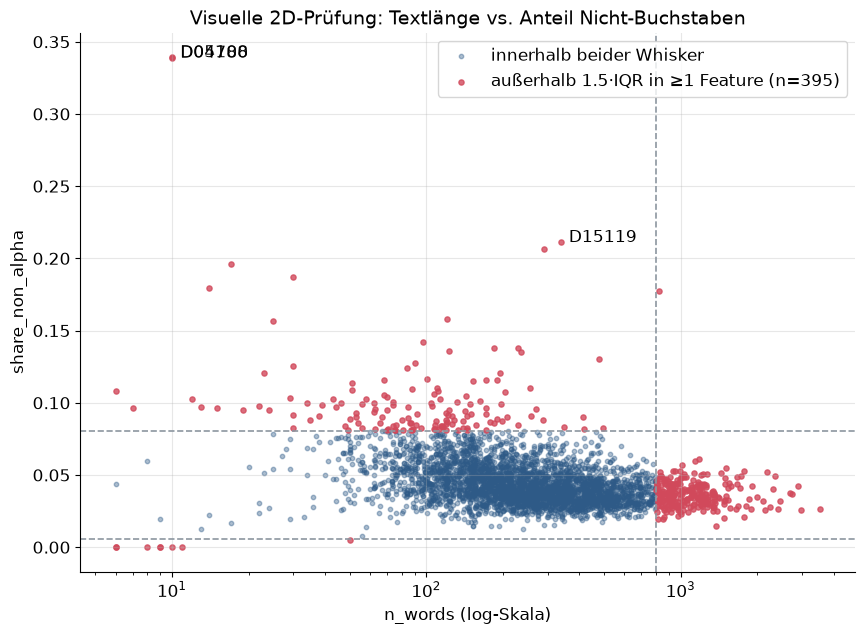

In [8]:
# Bivariate visuelle Prüfung: n_words vs. share_non_alpha
lo_w, hi_w = O.iqr_bounds(feat["n_words"])
lo_n, hi_n = O.iqr_bounds(feat["share_non_alpha"])
flag2d = iqr15["n_words"] | iqr15["share_non_alpha"]
fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(feat.loc[~flag2d, "n_words"], feat.loc[~flag2d, "share_non_alpha"], s=10, alpha=0.4,
           color=PALETTE["main"], label="innerhalb beider Whisker")
ax.scatter(feat.loc[flag2d, "n_words"], feat.loc[flag2d, "share_non_alpha"], s=14, alpha=0.8,
           color=PALETTE["outlier"], label=f"außerhalb 1.5·IQR in ≥1 Feature (n={flag2d.sum()})")
ax.axvline(hi_w, color=PALETTE["grey"], ls="--", lw=1.2)
ax.axhline(hi_n, color=PALETTE["grey"], ls="--", lw=1.2)
if lo_n > 0:
    ax.axhline(lo_n, color=PALETTE["grey"], ls="--", lw=1.2)
ax.set_xscale("log")
ax.set_xlabel("n_words (log-Skala)")
ax.set_ylabel("share_non_alpha")
ax.set_title("Visuelle 2D-Prüfung: Textlänge vs. Anteil Nicht-Buchstaben")
for _, r in feat.nlargest(3, "share_non_alpha").iterrows():
    ax.annotate(r["id"], (r["n_words"], r["share_non_alpha"]), fontsize=12,
                xytext=(6, 0), textcoords="offset points")
ax.legend(loc="upper right")
save_fig(fig, "scatter_length_vs_nonalpha", FIG)
plt.show()

**Interpretation:** Mit $k = 1.5$ markiert die Regel pro Feature zwischen 17 und 318 Briefe. Zusammen sind es 1.419 Briefe
(37 %), die in mindestens einem der 13 Features auffallen. Bei $k = 3.0$ sinkt die Zahl z. B. für `avg_word_len` von 110 auf 4.
Das zeigt, wie subjektiv der Faktor ist. Bei `n_attachments` und `n_cases` ist $IQR = 0$, dort gilt jeder vom Normalfall
abweichende Wert als Ausreißer, unabhängig von $k$. Für den Methodenvergleich verwenden wir `iqr_any` deshalb nur über die
9 stetigen Features. Im Scatterplot fallen zwei sehr kurze „Briefe“ mit rund 34 % Nicht-Buchstaben auf, nämlich bloße
Archivverweise (z. B. „s. AAV Arch. Nunz. Romania 92, fasc. 506 …“).

## 4. Normalitätscheck mit QQ-Plots  *[Vorlesung]*

**Was:** QQ-Plots (`statsmodels.api.qqplot`, `line='q'` = Linie durch das 25-%- und 75-%-Quantil) für die 9 stetigen Features.
Features mit $|\text{skew}| > 1$ werden per `log1p` transformiert und erneut geprüft. Zusätzlich Shapiro-Wilk auf einer
Zufallsstichprobe von $n = 500$.

**Warum / Vorlesung:** Folie „Parametric Methods: Prerequisites“: *Niemals* parametrische Verfahren (z-Score, Mahalanobis + χ²)
anwenden, ohne vorher Normalität zu prüfen. Die diskreten Zähl-Features `n_languages`, `n_attachments`, `n_cases` (fast nur 0/1)
und `year` (Kalenderjahr) sind nicht sinnvoll als stetig-normal modellierbar und bleiben hier außen vor.

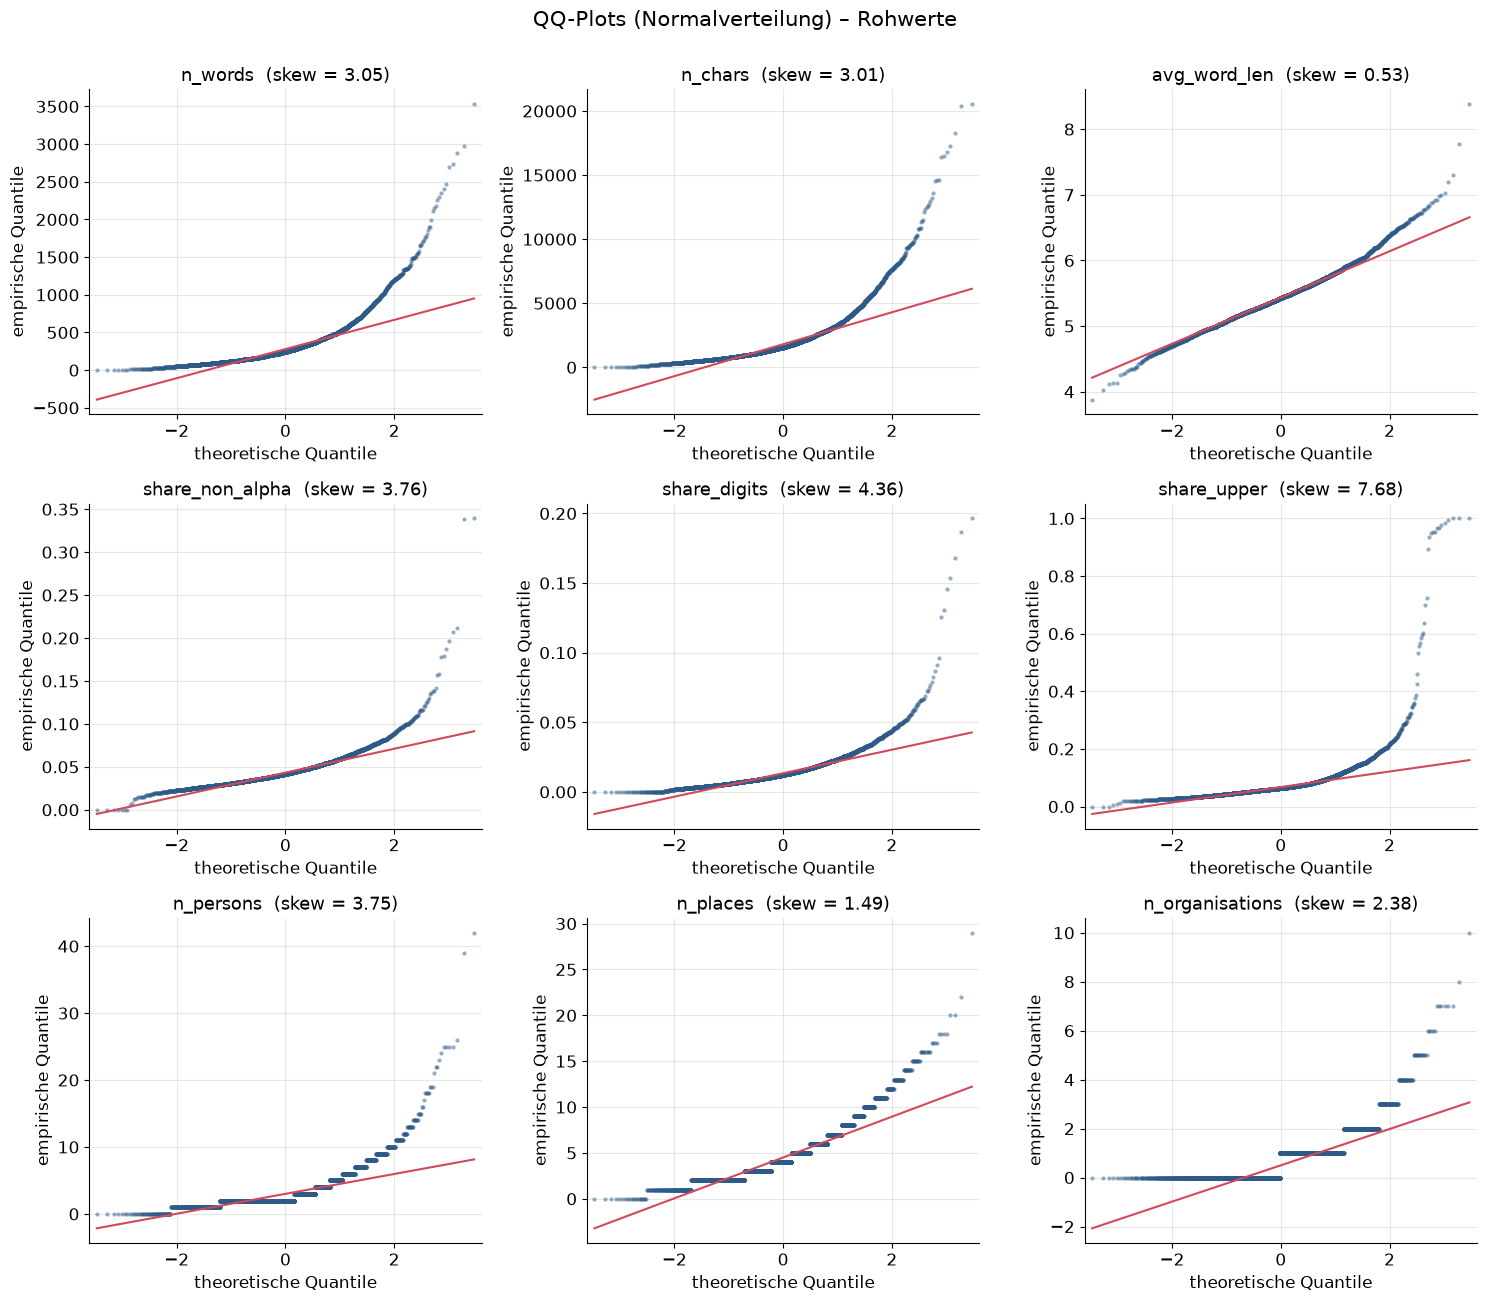

In [9]:
def qq_grid(data, cols, title, fname):
    fig, axes = plt.subplots(3, 3, figsize=(15, 13))
    for ax, c in zip(axes.flat, cols):
        sm.qqplot(data[c].dropna(), line="q", ax=ax, markersize=3, alpha=0.5,
                  markerfacecolor=PALETTE["main"], markeredgecolor="none")
        ax.get_lines()[1].set_color(PALETTE["outlier"])
        ax.set_title(f"{c}  (skew = {stats.skew(data[c].dropna()):.2f})", fontsize=13)
        ax.set_xlabel("theoretische Quantile")
        ax.set_ylabel("empirische Quantile")
    fig.suptitle(title, y=1.0)
    fig.tight_layout()
    save_fig(fig, fname, FIG)
    plt.show()

qq_grid(feat, CONT, "QQ-Plots (Normalverteilung) – Rohwerte", "qq_all_before")

In [10]:
skew_before = O.skew_table(feat, CONT)
LOG_COLS = [c for c in CONT if abs(skew_before[c]) > 1]
feat_t = feat[CONT].copy()
for c in LOG_COLS:
    feat_t[c] = np.log1p(feat_t[c])
skew_after = O.skew_table(feat_t, CONT)
kurt_after = feat_t.apply(lambda s: stats.kurtosis(s))

sample_idx = feat.sample(500, random_state=RANDOM_STATE).index
sw_before = {c: stats.shapiro(feat.loc[sample_idx, c]).pvalue for c in CONT}
sw_after = {c: stats.shapiro(feat_t.loc[sample_idx, c]).pvalue for c in CONT}

skew_tab = pd.DataFrame({
    "skew vorher": skew_before, "log1p?": [c in LOG_COLS for c in CONT],
    "skew nachher": skew_after, "Exzess-Kurtosis nachher": kurt_after,
    "Shapiro p vorher (n=500)": pd.Series(sw_before), "Shapiro p nachher (n=500)": pd.Series(sw_after),
    "eindeutige Werte": feat[CONT].nunique(),
})
skew_tab.to_csv(RES / "skewness_before_after.csv")
display(skew_tab.style.format({"skew vorher": "{:.2f}", "skew nachher": "{:.2f}",
                               "Exzess-Kurtosis nachher": "{:.2f}",
                               "Shapiro p vorher (n=500)": "{:.1e}", "Shapiro p nachher (n=500)": "{:.1e}"}))
STATS["skewness"] = {"before": skew_before.round(3).to_dict(), "after": skew_after.round(3).to_dict(),
                     "log1p_transformed": LOG_COLS}

,skew vorher,log1p?,skew nachher,Exzess-Kurtosis nachher,Shapiro p vorher (n=500),Shapiro p nachher (n=500),eindeutige Werte
n_words,3.05,True,-0.27,1.10,1.4e-26,1.3e-06,904
n_chars,3.01,True,-0.29,1.20,1.8e-26,3.1e-07,2476
avg_word_len,0.53,False,0.53,1.87,1.3e-05,1.3e-05,3531
share_non_alpha,3.76,True,3.17,28.17,2.7e-13,1.4e-12,3613
share_digits,4.36,True,3.95,35.37,1.1e-18,2.4e-18,3521
share_upper,7.68,True,5.82,51.80,1.5e-31,1.0e-28,3673
n_persons,3.75,True,0.62,1.31,2.1e-25,1.2e-16,28
n_places,1.49,True,-0.01,0.08,1.7e-17,8.7e-08,22
n_organisations,2.38,True,0.63,-0.34,6.5e-27,8.3e-26,10


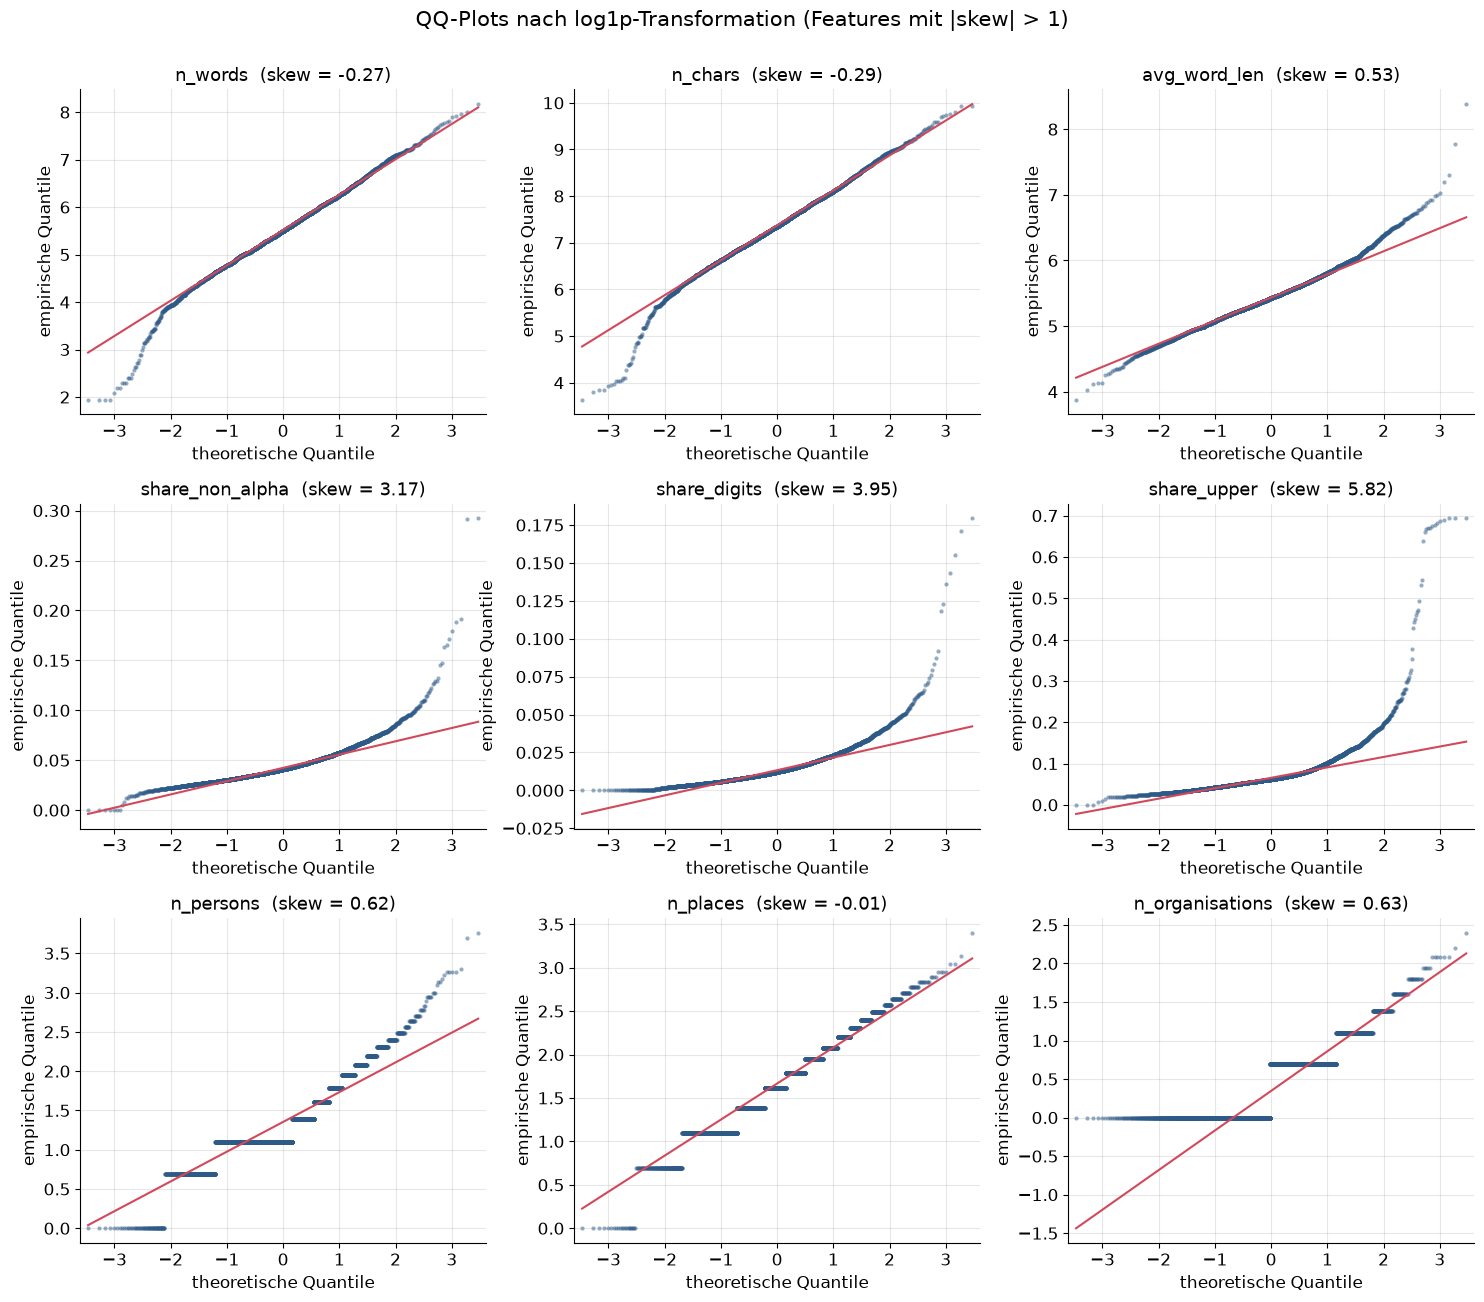

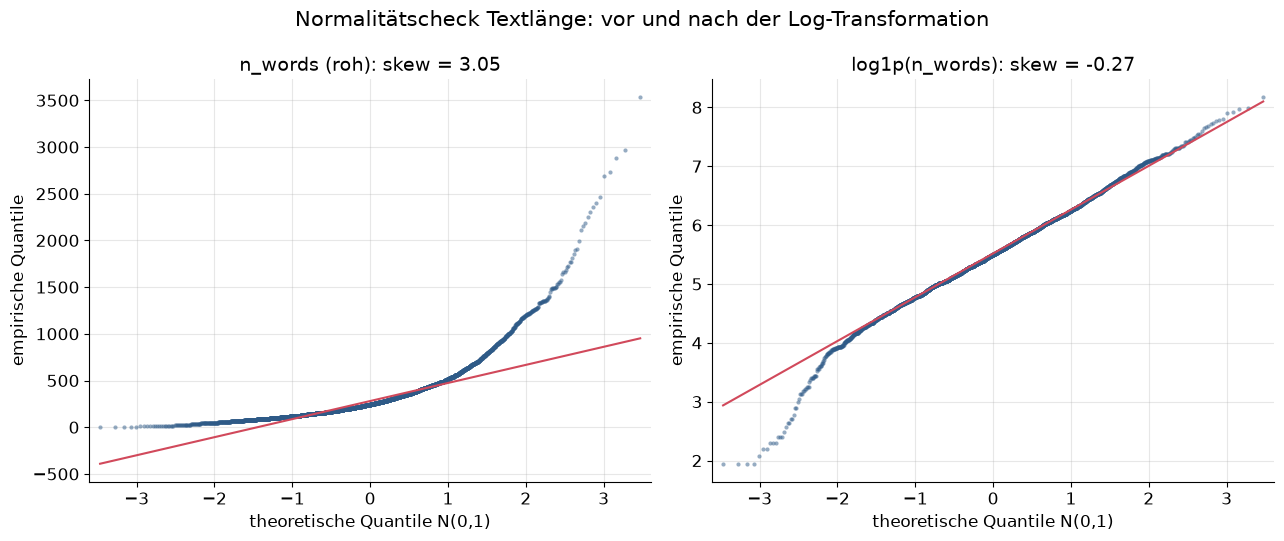

In [11]:
qq_grid(feat_t, CONT, "QQ-Plots nach log1p-Transformation (Features mit |skew| > 1)", "qq_all_after")

# zentraler Folien-Plot: n_words vorher / nachher
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, data, ttl in [(axes[0], feat["n_words"], "n_words (roh)"),
                      (axes[1], np.log1p(feat["n_words"]), "log1p(n_words)")]:
    sm.qqplot(data, line="q", ax=ax, markersize=3, alpha=0.5,
              markerfacecolor=PALETTE["main"], markeredgecolor="none")
    ax.get_lines()[1].set_color(PALETTE["outlier"])
    ax.set_title(f"{ttl}: skew = {stats.skew(data):.2f}")
    ax.set_xlabel("theoretische Quantile N(0,1)")
    ax.set_ylabel("empirische Quantile")
fig.suptitle("Normalitätscheck Textlänge: vor und nach der Log-Transformation")
fig.tight_layout()
save_fig(fig, "qq_before_after_n_words", FIG)
plt.show()

**Interpretation:** Vor der Transformation sind 8 der 9 Features deutlich rechtsschief (skew 1,5 bis 7,7). Nach `log1p` sind
`n_words` (−0,27), `n_chars`, `n_places` (−0,01), `n_persons` und `n_organisations` annähernd symmetrisch, und der QQ-Plot von `n_words`
wird fast zur Geraden. Die drei Anteils-Features (`share_*`) bleiben stark schief und haben eine Kurtosis von 28 bis 52:
Bei Werten nahe 0 ist $\log(1+x) \approx x$, die Transformation wirkt dort also kaum. Shapiro-Wilk lehnt trotz Stichprobe fast überall ab.
Bei großem $n$ entdecken solche Tests schon kleinste Abweichungen, deshalb sind QQ-Plot und Skewness hier aussagekräftiger.

## 5. Univariater z-Score  *[Vorlesung]*

**Was:** $z = (x - \bar x)/s$ auf den (ggf. log-transformierten) Features, Ausreißer bei $|z| > 3.5$ (Vorlesungs-Faustregel,
Tail-Wahrscheinlichkeit $\ll 0.05\,\%$).

**Auswahl der Features (Voraussetzung Normalität):** nur Features, die nach Schritt 4 *annähernd normal* sind.
Transparente Regel: $|\text{skew}| < 0.75$ **und** $|\text{Exzess-Kurtosis}| < 2$ **und** ≥ 15 verschiedene Werte (sehr grob
diskrete Zählwerte erzeugen treppenförmige QQ-Plots). Ausgeschlossen werden damit die `share_*`-Features (stark schief und
schwere Ränder: der z-Score würde dort systematisch zu viele Briefe markieren) und `n_organisations` (nur wenige verschiedene Werte).

In [12]:
ZSCORE_COLS = [c for c in CONT
               if abs(skew_after[c]) < 0.75 and abs(kurt_after[c]) < 2 and feat[c].nunique() >= 15]
print("z-Score auf:", ZSCORE_COLS)
print("ausgeschlossen:", [c for c in CONT if c not in ZSCORE_COLS])
Z_uni = (feat_t[ZSCORE_COLS] - feat_t[ZSCORE_COLS].mean()) / feat_t[ZSCORE_COLS].std()
z_flags = Z_uni.abs() > 3.5
zscore_any = z_flags.any(axis=1)
z_tab = pd.DataFrame({"|z| > 3.5": z_flags.sum(), "davon z < −3.5": (Z_uni < -3.5).sum(),
                      "davon z > +3.5": (Z_uni > 3.5).sum()})
display(z_tab)
print(f"zscore_any: {zscore_any.sum()} Briefe")
STATS["zscore"] = {"features": ZSCORE_COLS, "per_feature": z_flags.sum().astype(int).to_dict(),
                   "any": int(zscore_any.sum())}

z-Score auf: ['n_words', 'n_chars', 'avg_word_len', 'n_persons', 'n_places']
ausgeschlossen: ['share_non_alpha', 'share_digits', 'share_upper', 'n_organisations']


,|z| > 3.5,davon z < −3.5,davon z > +3.5
n_words,19,19,0
n_chars,20,20,0
avg_word_len,13,2,11
n_persons,12,0,12
n_places,1,0,1


zscore_any: 45 Briefe


**Interpretation:** Der z-Score markiert nur 45 Briefe gegenüber 1.143 bei der IQR-Regel, weil er auf 5 annähernd normalen
Features läuft und mit 3,5σ eine strenge Grenze hat. Bei `log(n_words)` liegen alle 19 Treffer im unteren Rand ($z < -3.5$): Das sind
sehr kurze Fragmente. Durch die Log-Transformation werden lange Briefe nicht mehr automatisch zu Ausreißern.
Bei `n_persons` (12) und `avg_word_len` (11) liegen die Treffer dagegen am oberen Rand.

## 6. Multivariat: Mahalanobis-Distanz + χ²-Plot  *[Vorlesung]*

**Was:** Auf den standardisierten, log-transformierten stetigen Features (ohne `year`, ohne Bool-Spalten) wird
$d^2_j = (x_j - \bar x)^\top \Sigma^{-1} (x_j - \bar x)$ berechnet. Unter multivariater Normalverteilung gilt $d^2 \sim \chi^2_p$.
χ²-Plot: geordnete $d^2_{(j)}$ gegen $q_p\big((j - 0.5)/n\big)$, Referenzlinie mit Steigung 1, Grenze beim 99,5-%-Quantil von $\chi^2_p$.

**Vergleich:** naive euklidische Distanz $\hat d^2 = (x - \bar x)^\top (x - \bar x)$ ohne $\Sigma^{-1}$. Laut Vorlesung nimmt sie
eine *sphärische* Punktwolke an und liefert bei korrelierten Daten unerwartete Ergebnisse.

**Wichtige Entscheidung:** `n_chars` wird **nicht** aufgenommen. Mit r = 0,997 zu `n_words` (und im Log-Raum fast exakt
$\log n_{chars} \approx \log n_{words} + \log(\text{avg\_word\_len}+1)$) wäre Σ nahezu singulär (Konditionszahl ≈ 72.000 statt ≈ 19),
und $\Sigma^{-1}$ würde winzige Abweichungen extrem verstärken. Damit gilt $p = 8$.

p = 8; Konditionszahl Σ: mit n_chars 71,679, ohne 19.0
χ²_8-Grenze (99,5 %): 21.95
Mahalanobis klassisch: 128 | euklidisch: 149 | Überschneidung: 104


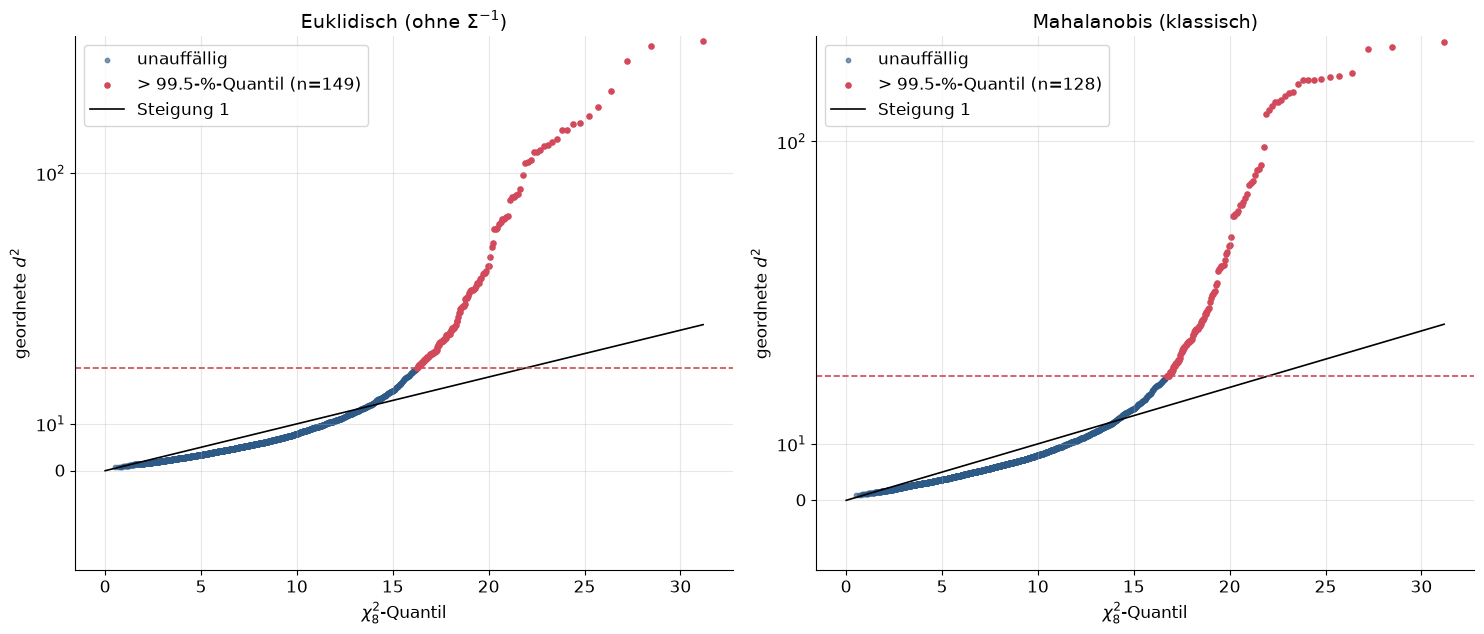

In [13]:
MV_COLS = [c for c in CONT if c != "n_chars"]
X_t = feat_t[MV_COLS]
X = ((X_t - X_t.mean()) / X_t.std()).to_numpy()
p = X.shape[1]
cov_cl = np.cov(X, rowvar=False)
cond_with = np.linalg.cond(np.cov(((feat_t[CONT] - feat_t[CONT].mean()) / feat_t[CONT].std()).to_numpy(), rowvar=False))
print(f"p = {p}; Konditionszahl Σ: mit n_chars {cond_with:,.0f}, ohne {np.linalg.cond(cov_cl):.1f}")

CUTOFF = stats.chi2.ppf(0.995, df=p)
d2_classic = O.mahalanobis_sq(X, X.mean(axis=0), cov_cl)
d2_euclid = ((X - X.mean(axis=0)) ** 2).sum(axis=1)
maha_classic = pd.Series(d2_classic > CUTOFF, index=feat.index)
euclid_flag = pd.Series(d2_euclid > CUTOFF, index=feat.index)
print(f"χ²_{p}-Grenze (99,5 %): {CUTOFF:.2f}")
print(f"Mahalanobis klassisch: {maha_classic.sum()} | euklidisch: {euclid_flag.sum()} | "
      f"Überschneidung: {(maha_classic & euclid_flag).sum()}")

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
O.chi2_plot(axes[0], d2_euclid, p, "Euklidisch (ohne $\\Sigma^{-1}$)")
O.chi2_plot(axes[1], d2_classic, p, "Mahalanobis (klassisch)")
fig.tight_layout()
save_fig(fig, "chi2_euclid_vs_classic", FIG)
plt.show()
STATS["mahalanobis"] = {"features": MV_COLS, "p": p, "chi2_cutoff_99.5": round(float(CUTOFF), 3),
                        "euclid": int(euclid_flag.sum()), "classic": int(maha_classic.sum()),
                        "cond_cov_with_n_chars": round(float(cond_with), 1)}

**Interpretation:** Im χ²-Plot liegen die Punkte nur im unteren Bereich auf der Steigung-1-Linie. Rechts biegen sie stark nach oben
ab. Die Daten sind also nicht multivariat normal, vor allem wegen der schweren Ränder der `share_*`-Features. Damit ist auch das
99,5-%-Quantil nur eine Richtgröße. Die euklidische Distanz markiert mehr Briefe als die Mahalanobis-Distanz, und die Mengen sind
nicht identisch: Ohne $\Sigma^{-1}$ werden korrelierte Abweichungen (z. B. viele Personen *und* viele Orte) doppelt gezählt,
während untypische *Kombinationen* von Werten untergewichtet werden.

## 7. Robuste Mahalanobis-Distanz (MCD)  *[Erweiterung, nicht Vorlesung]*

**Was:** Statt $\bar x$ und der empirischen Kovarianz schätzt der *Minimum Covariance Determinant* (`sklearn.covariance.MinCovDet`)
Lage und Streuung aus der Teilmenge von Beobachtungen mit dem kleinsten Determinanten-Volumen, also aus dem „sauberen“ Kern der Daten.
Gleicher χ²-Plot, gleiche Grenze.

**Warum:** Ausreißer verzerren $\bar x$ und $\Sigma$ selbst. Sie blähen $\Sigma$ auf und senken dadurch ihre eigene Distanz.
Dieser **Masking-Effekt** kann Ausreißer verstecken. Die Vorlesung nennt als Nachteil, dass Σ nur empirisch geschätzt wird;
MCD ist die etablierte Antwort darauf.

MCD-Kern: 3037 von 3839 Briefen
Robust: 533 | klassisch: 128 | klassisch ⊂ robust: 128 von 128


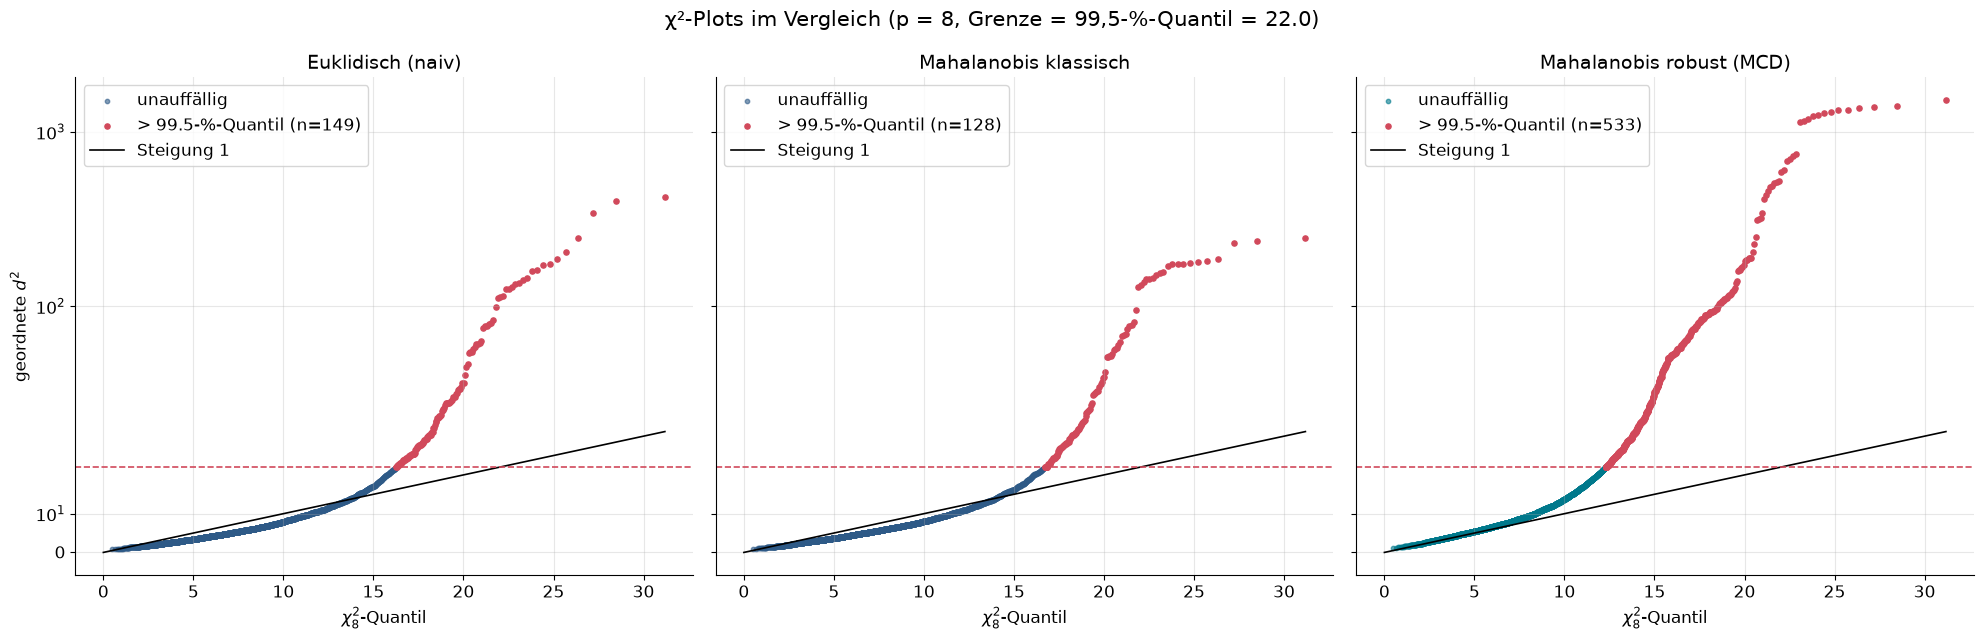

,Mittelwert klassisch,Lage MCD,SD klassisch,SD MCD
n_words,-0.0,0.180,1.0,0.885
avg_word_len,-0.0,-0.039,1.0,0.894
share_non_alpha,-0.0,-0.251,1.0,0.605
share_digits,0.0,-0.238,1.0,0.571
share_upper,-0.0,-0.273,1.0,0.357
n_persons,0.0,-0.003,1.0,0.913
n_places,0.0,0.095,1.0,0.975
n_organisations,0.0,-0.066,1.0,0.970


In [14]:
from sklearn.covariance import MinCovDet

mcd = MinCovDet(random_state=RANDOM_STATE).fit(X)
d2_robust = mcd.mahalanobis(X)
maha_robust = pd.Series(d2_robust > CUTOFF, index=feat.index)
print(f"MCD-Kern: {mcd.support_.sum()} von {len(X)} Briefen")
print(f"Robust: {maha_robust.sum()} | klassisch: {maha_classic.sum()} | "
      f"klassisch ⊂ robust: {(maha_classic & maha_robust).sum()} von {maha_classic.sum()}")

fig, axes = plt.subplots(1, 3, figsize=(20, 6.5), sharey=True)
O.chi2_plot(axes[0], d2_euclid, p, "Euklidisch (naiv)")
O.chi2_plot(axes[1], d2_classic, p, "Mahalanobis klassisch")
O.chi2_plot(axes[2], d2_robust, p, "Mahalanobis robust (MCD)", color=PALETTE["teal"])
for ax in axes[1:]:
    ax.set_ylabel("")
fig.suptitle(f"χ²-Plots im Vergleich (p = {p}, Grenze = 99,5-%-Quantil = {CUTOFF:.1f})")
fig.tight_layout()
save_fig(fig, "chi2_euclid_classic_robust", FIG)
plt.show()

shift = pd.DataFrame({"Mittelwert klassisch": X.mean(axis=0), "Lage MCD": mcd.location_,
                      "SD klassisch": np.sqrt(np.diag(cov_cl)), "SD MCD": np.sqrt(np.diag(mcd.covariance_))},
                     index=MV_COLS).round(3)
display(shift)
STATS["mahalanobis"]["robust_mcd"] = int(maha_robust.sum())
STATS["mahalanobis"]["mcd_support_size"] = int(mcd.support_.sum())

**Interpretation:** Der Masking-Effekt ist deutlich sichtbar: Die robuste Distanz markiert ein Vielfaches der klassisch markierten Briefe,
und fast alle klassisch markierten Briefe sind darin enthalten. Die Tabelle zeigt warum: Besonders bei den `share_*`-Features ist
die MCD-Standardabweichung viel kleiner als die klassische, weil wenige Extremwerte die klassische Kovarianz aufblähen.
Die hohe Zahl robuster Treffer ist aber auch ein Zeichen der verletzten Normalannahme. Die schweren Ränder liegen *jenseits*
eines engen Kerns, deshalb ist die χ²-Grenze hier eher zu streng als zu locker.

## 8. Depth-based: Convex Hull Peeling  *[Vorlesung]*

**Was:** Iteratives Schälen konvexer Hüllen (`scipy.spatial.ConvexHull`): Alle Punkte auf der Hülle erhalten Layer $L$, werden
entfernt, $L \leftarrow L+1$, bis weniger als 3 Punkte übrig sind. Die **äußeren 2 Layer** gelten als Ausreißer.

**Ohne Dimensionsreduktion:** Das Verfahren wird in 2D auf zwei inhaltlich sinnvollen Feature-Paaren ausgeführt:
(a) `log(n_words)` vs. `share_non_alpha` (Länge vs. „Nicht-Text“) und (b) `log(n_words)` vs. `n_persons` (Länge vs. Personendichte).
Konvexe Hüllen sind affin invariant, eine Standardisierung ändert die Layer daher nicht. `hull` = Ausreißer in mindestens einem der beiden Paare.
Punkte mit identischen Koordinaten wie ein Hüllen-Eckpunkt werden derselben Schicht zugeordnet.

log(n_words) vs. share_non_alpha: 140 Layer, 0.34 s, Ausreißer (Layer 1–2): 19


log(n_words) vs. n_persons: 233 Layer, 0.58 s, Ausreißer (Layer 1–2): 26
hull (Vereinigung): 37 Briefe


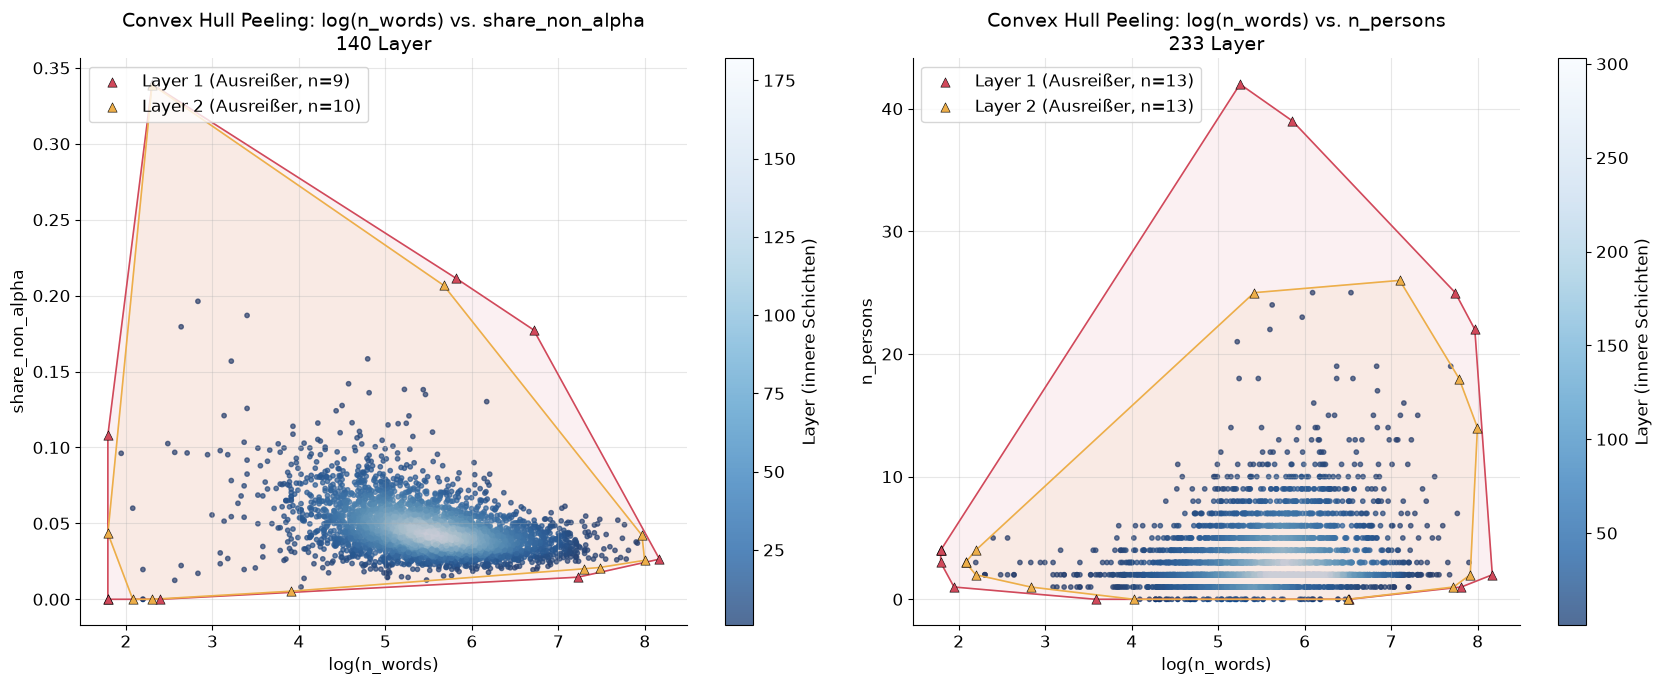

In [15]:
from scipy.spatial import ConvexHull

PAIRS = [("n_words", "share_non_alpha"), ("n_words", "n_persons")]
hull_layers, hull_flags, hull_time = {}, {}, {}
for a, b in PAIRS:
    P = np.column_stack([np.log(feat[a]), feat[b]])
    t0 = time.time()
    layers = O.convex_hull_peeling(P)
    hull_time[(a, b)] = time.time() - t0
    hull_layers[(a, b)] = layers
    hull_flags[(a, b)] = pd.Series(layers <= 2, index=feat.index)
    print(f"log({a}) vs. {b}: {layers.max()} Layer, {hull_time[(a, b)]:.2f} s, "
          f"Ausreißer (Layer 1–2): {(layers <= 2).sum()}")
hull = hull_flags[PAIRS[0]] | hull_flags[PAIRS[1]]
print(f"hull (Vereinigung): {hull.sum()} Briefe")

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, (a, b) in zip(axes, PAIRS):
    P = np.column_stack([np.log(feat[a]), feat[b]])
    layers = hull_layers[(a, b)]
    inner = layers > 2
    sc = ax.scatter(P[inner, 0], P[inner, 1], c=layers[inner], cmap="Blues_r", s=10, alpha=0.7,
                    vmin=1, vmax=layers.max() * 1.3)
    for L, col, mk in [(1, PALETTE["outlier"], "^"), (2, PALETTE["accent"], "^")]:
        m = layers == L
        ax.scatter(P[m, 0], P[m, 1], color=col, marker=mk, s=45, edgecolor="black", lw=0.4,
                   label=f"Layer {L} (Ausreißer, n={m.sum()})", zorder=3)
        h = ConvexHull(P[layers >= L])
        pts = P[layers >= L][h.vertices]
        ax.fill(pts[:, 0], pts[:, 1], color=col, alpha=0.08, zorder=1)
        ax.plot(np.r_[pts[:, 0], pts[0, 0]], np.r_[pts[:, 1], pts[0, 1]], color=col, lw=1.2, zorder=2)
    fig.colorbar(sc, ax=ax, label="Layer (innere Schichten)")
    ax.set_xlabel(f"log({a})")
    ax.set_ylabel(b)
    ax.set_title(f"Convex Hull Peeling: log({a}) vs. {b}\n{layers.max()} Layer")
    ax.legend(loc="upper left")
fig.tight_layout()
save_fig(fig, "hull_peeling", FIG)
plt.show()
STATS["hull"] = {f"log({a})_vs_{b}": {"n_layers": int(hull_layers[(a, b)].max()),
                                       "outliers_layer1_2": int(hull_flags[(a, b)].sum()),
                                       "runtime_s": round(hull_time[(a, b)], 2)} for a, b in PAIRS}
STATS["hull"]["union"] = int(hull.sum())

**Interpretation:** Die äußeren zwei Schichten enthalten jeweils nur wenige Briefe. Das sind die extremsten Kombinationen
(sehr kurz bzw. sehr lang, extrem viele Nicht-Buchstaben oder Personen). Alle Punkte einer Schicht gelten gleich viel, ein Brief
knapp auf Layer 2 zählt also wie das extremste Fragment. Das ist der in der Vorlesung genannte Nachteil der fehlenden
Differenzierung innerhalb eines Layers. In 2D ist das Verfahren mit Hunderten von Hüllen in Sekunden fertig. Der Rechenaufwand
der konvexen Hülle wächst aber stark mit der Dimension ($O(n^{\lfloor d/2 \rfloor})$), deshalb ist es nur in niedriger Dimension
praktikabel. Ohne Dimensionsreduktion bleibt uns daher nur die paarweise 2D-Anwendung.

## 9. Angle-based: ABOD  *[Vorlesung]*

**Was:** *Angle-Based Outlier Degree* (`pyod.models.abod.ABOD(method='fast', n_neighbors=20)`) auf denselben standardisierten
log-Features wie in Schritt 6 ($p = 8$). Für jeden Punkt $x$ wird die (distanzgewichtete) **Varianz der Winkel** zu Paaren
anderer Punkte berechnet. In der *fast*-Variante werden nur die 20 nächsten Nachbarn genutzt.

**Vorlesung:** Punkte im Inneren „sehen“ ihre Nachbarn in allen Richtungen (hohe Winkelvarianz). Ausreißer sehen den Rest der Daten
unter ähnlichen Winkeln (niedrige Varianz). **Niedriger ABOD-Wert = Ausreißer.** `pyod` speichert intern $-\text{ABOF}$
(höher = auffälliger); wir drehen das Vorzeichen zurück. Markiert werden die 1 % mit dem niedrigsten ABOF.

In [16]:
from pyod.models.abod import ABOD

t0 = time.time()
abod_model = ABOD(method="fast", n_neighbors=20).fit(X)
abof = -abod_model.decision_scores_          # ABOF: niedrig = Ausreißer
print(f"ABOD: {time.time() - t0:.1f} s, NaN/inf: {np.sum(~np.isfinite(abof))}")
abod_cut = np.quantile(abof, 0.01)
abod = pd.Series(abof <= abod_cut, index=feat.index)
print(f"ABOD Top-1 %: {abod.sum()} Briefe (ABOF ≤ {abod_cut:.2e})")
STATS["abod"] = int(abod.sum())

ABOD: 5.9 s, NaN/inf: 0
ABOD Top-1 %: 39 Briefe (ABOF ≤ 6.02e-04)


**Interpretation:** ABOD ist ohne Verteilungsannahme und im Prinzip für höhere Dimensionen gedacht. Die Verteilung der ABOF-Werte
erstreckt sich über mehrere Größenordnungen (Histogramm in Schritt 11, log-Skala). Die markierten 1 % liegen klar im unteren Rand.
Die Überschneidung mit den Distanzverfahren folgt im Methodenvergleich (Schritt 12).

## 10. Isolation Forest  *[Erweiterung, nicht Vorlesung]*

**Was:** `sklearn.ensemble.IsolationForest(n_estimators=300, contamination=0.01)` auf denselben Features. Der Wald isoliert Punkte durch
**zufällige Splits** (zufälliges Feature, zufälliger Schwellwert). Ausreißer liegen abseits und sind nach **wenigen Splits** isoliert,
haben also eine kurze mittlere Pfadlänge. Der Wald braucht keine Verteilungsannahme, skaliert linear mit $n$ und ist der Standard in der Praxis.

In [17]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(n_estimators=300, contamination=0.01, random_state=RANDOM_STATE).fit(X)
iforest_score = -iso.score_samples(X)        # höher = auffälliger
iforest = pd.Series(iso.predict(X) == -1, index=feat.index)
print(f"Isolation Forest: {iforest.sum()} Briefe markiert")
STATS["iforest"] = int(iforest.sum())

Isolation Forest: 39 Briefe markiert


**Interpretation:** Der Isolation Forest markiert per Konstruktion 1 % der Briefe (39). Da die Splits achsenparallel sind, fallen
Briefe auf, die in *einzelnen* Features extrem sind: 62 % der Treffer haben einen extremen Großbuchstaben-Anteil, 56 % einen extremen
Ziffernanteil (jeweils über dem 3·IQR-Zaun), und 15 der 22 Telegramme in Versalien sind dabei. Das Profil ähnelt stark dem von ABOD
(Jaccard 0,53, siehe Schritt 12).

## 11. Local Outlier Factor (LOF)  *[Erweiterung, nicht Vorlesung]*

**Was:** `sklearn.neighbors.LocalOutlierFactor(n_neighbors=20, contamination=0.01)`. LOF vergleicht die **lokale Dichte** eines Punktes
(Erreichbarkeitsdistanz zu den 20 Nachbarn) mit der Dichte seiner Nachbarn. LOF ≫ 1 heißt: deutlich dünner besiedelt als die Umgebung.
Dadurch findet LOF auch Punkte, die *global* unauffällig sind, aber lokal am Rand eines dichten Clusters liegen (lokal statt global).

LOF: 39 Briefe markiert, LOF-Grenze ≈ 1.73


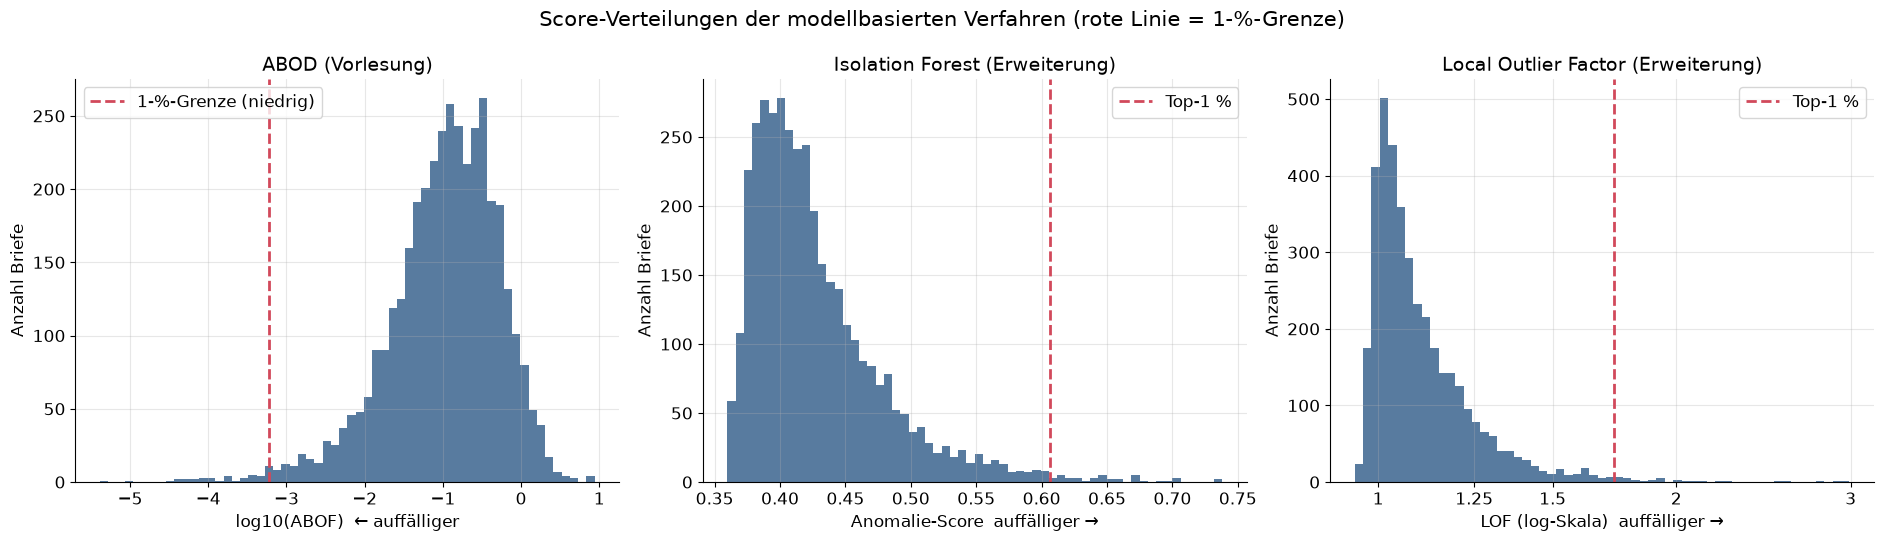

In [18]:
from sklearn.neighbors import LocalOutlierFactor

lof_model = LocalOutlierFactor(n_neighbors=20, contamination=0.01)
lof_pred = lof_model.fit_predict(X)
lof_score = -lof_model.negative_outlier_factor_  # LOF, höher = auffälliger
lof = pd.Series(lof_pred == -1, index=feat.index)
print(f"LOF: {lof.sum()} Briefe markiert, LOF-Grenze ≈ {np.sort(lof_score)[-lof.sum()]:.2f}")
STATS["lof"] = int(lof.sum())

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
ax = axes[0]
ax.hist(np.log10(abof), bins=60, color=PALETTE["main"], alpha=0.8)
ax.axvline(np.log10(abod_cut), color=PALETTE["outlier"], ls="--", lw=2, label="1-%-Grenze (niedrig)")
ax.set_xlabel("log10(ABOF)  ← auffälliger")
ax.set_title("ABOD (Vorlesung)")
ax = axes[1]
ax.hist(iforest_score, bins=60, color=PALETTE["main"], alpha=0.8)
ax.axvline(np.sort(iforest_score)[-iforest.sum()], color=PALETTE["outlier"], ls="--", lw=2, label="Top-1 %")
ax.set_xlabel("Anomalie-Score  auffälliger →")
ax.set_title("Isolation Forest (Erweiterung)")
ax = axes[2]
ax.hist(lof_score, bins=np.logspace(np.log10(lof_score.min()), np.log10(lof_score.max()), 60),
        color=PALETTE["main"], alpha=0.8)
ax.set_xscale("log")
ticks = [t for t in [0.9, 1, 1.25, 1.5, 2, 3, 4, 6] if lof_score.min() <= t <= lof_score.max() * 1.05]
ax.set_xticks(ticks, [f"{t:g}" for t in ticks])
ax.minorticks_off()
ax.axvline(np.sort(lof_score)[-lof.sum()], color=PALETTE["outlier"], ls="--", lw=2, label="Top-1 %")
ax.set_xlabel("LOF (log-Skala)  auffälliger →")
ax.set_title("Local Outlier Factor (Erweiterung)")
for ax in axes:
    ax.set_ylabel("Anzahl Briefe")
    ax.legend()
fig.suptitle("Score-Verteilungen der modellbasierten Verfahren (rote Linie = 1-%-Grenze)")
fig.tight_layout()
save_fig(fig, "score_histograms", FIG)
plt.show()

**Interpretation:** Die meisten LOF-Werte liegen nahe 1, die Briefe sind also ähnlich dicht wie ihre Nachbarn. Nur ein langer
rechter Rand ist deutlich dünner besiedelt. Die drei Score-Verteilungen haben ganz unterschiedliche Formen, und die 1-%-Grenze
ist bei allen drei eine *gesetzte* Kontamination und kein natürlicher Bruch. Die Zahl der Treffer ist damit wie beim IQR-Faktor
eine subjektive Entscheidung.

## 12. Methodenvergleich

**Was:** Eine Zeile pro Brief, je Methode eine Bool-Spalte. `n_flags_lecture` zählt nur die Vorlesungsmethoden
(`iqr_any`, `zscore_any`, `maha_classic`, `hull`, `abod`), `n_flags_all` alle acht. Überlappung als **Jaccard-Index**
$|A \cap B| / |A \cup B|$ zwischen den markierten Mengen.

In [19]:
LECTURE = ["iqr_any", "zscore_any", "maha_classic", "hull", "abod"]
EXTENSION = ["maha_robust", "iforest", "lof"]
METHODS = ["iqr_any", "zscore_any", "maha_classic", "maha_robust", "hull", "abod", "iforest", "lof"]
ov = pd.DataFrame({"id": feat["id"], "iqr_any": iqr_any, "zscore_any": zscore_any,
                   "maha_classic": maha_classic, "maha_robust": maha_robust, "hull": hull,
                   "abod": abod, "iforest": iforest, "lof": lof})
ov["n_flags_lecture"] = ov[LECTURE].sum(axis=1)
ov["n_flags_all"] = ov[METHODS].sum(axis=1)
# Scores für spätere Sortierung / Nachvollziehbarkeit
ov["d2_classic"] = d2_classic.round(3)
ov["d2_robust"] = d2_robust.round(3)
ov["abof"] = abof
ov["iforest_score"] = iforest_score.round(4)
ov["lof_score"] = lof_score.round(3)
ov.to_csv(RES / "outlier_overview.csv", index=False)

counts = ov[METHODS].sum()
display(counts.rename("markiert").to_frame().T)
display(ov["n_flags_all"].value_counts().sort_index().rename("Briefe").to_frame().T)
STATS["n_flags_all_distribution"] = ov["n_flags_all"].value_counts().sort_index().astype(int).to_dict()

,iqr_any,zscore_any,maha_classic,maha_robust,hull,abod,iforest,lof
markiert,1143,45,128,533,37,39,39,39


n_flags_all,0,1,2,3,4,5,6,7,8
Briefe,2630,722,352,60,24,23,16,6,6


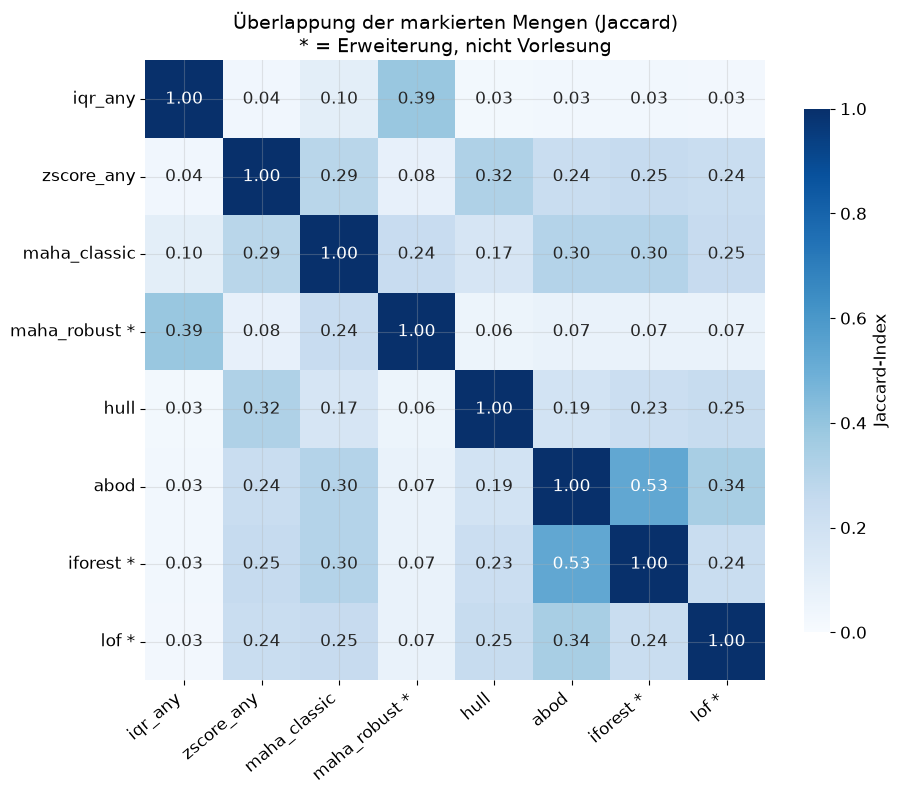

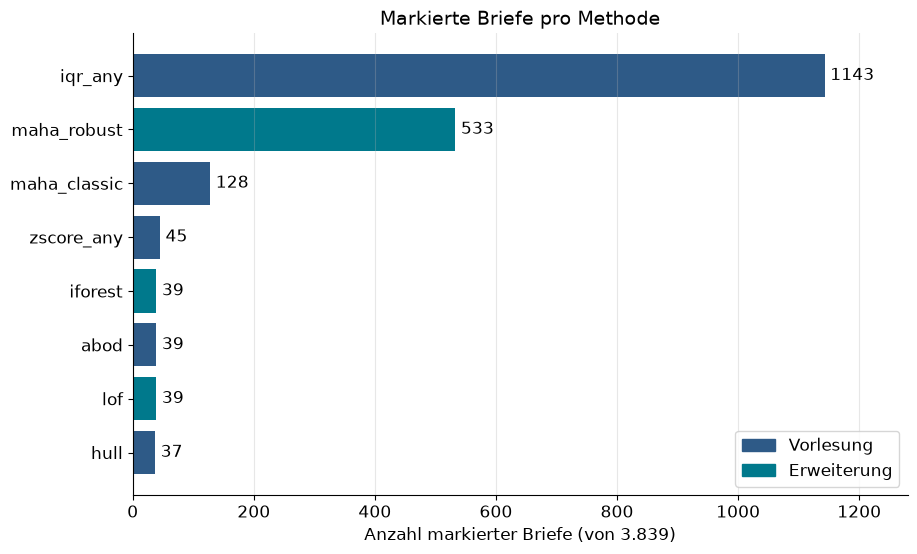

In [20]:
jac = O.jaccard_matrix(ov[METHODS])
labels = [f"{m} *" if m in EXTENSION else m for m in METHODS]
fig, ax = plt.subplots(figsize=(10, 8.5))
sns.heatmap(jac, annot=True, fmt=".2f", cmap=O.SEQ_CMAP, vmin=0, vmax=1, square=True,
            xticklabels=labels, yticklabels=labels, annot_kws={"size": 12},
            cbar_kws={"label": "Jaccard-Index", "shrink": 0.8}, ax=ax)
ax.set_title("Überlappung der markierten Mengen (Jaccard)\n* = Erweiterung, nicht Vorlesung")
plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
save_fig(fig, "method_overlap_heatmap", FIG)
plt.show()
jac.round(3).to_csv(RES / "method_jaccard.csv")

fig, ax = plt.subplots(figsize=(10, 6))
order = counts.sort_values().index
colors = [PALETTE["teal"] if m in EXTENSION else PALETTE["main"] for m in order]
bars = ax.barh(order, counts[order], color=colors)
ax.bar_label(bars, padding=4, fontsize=12)
ax.set_xlabel("Anzahl markierter Briefe (von 3.839)")
ax.set_title("Markierte Briefe pro Methode")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=PALETTE["main"], label="Vorlesung"),
                   Patch(color=PALETTE["teal"], label="Erweiterung")], loc="lower right")
ax.set_xlim(0, counts.max() * 1.12)
ax.grid(axis="y", visible=False)
save_fig(fig, "flags_per_method", FIG)
plt.show()

**Interpretation:** Die Methoden unterscheiden sich in der Menge um den Faktor 30: von 37 (`hull`) bis 1.143 (`iqr_any`).
Große Mengen haben mit kleinen zwangsläufig einen niedrigen Jaccard-Index (z. B. `iqr_any` vs. ABOD: 0,03). Am ähnlichsten sind
ABOD und Isolation Forest (0,53), die beide vor allem Briefe mit ungewöhnlicher Zeichenzusammensetzung finden (Telegramme, Ziffernkolonnen).
Die Hüllen-Methode ähnelt am ehesten dem z-Score (0,32), weil beide stark auf Textlänge reagieren. 32 % ihrer Treffer sind sehr lange,
38 % sehr kurze Texte. Kein Einzelverfahren deckt alles ab. Robuster ist der Konsens: 135 Briefe werden von ≥ 3 der 8 Methoden markiert.

## 13. Einordnung: Fehler vs. echter Sonderfall  *[Vorlesung: Behandlung ist kontextabhängig]*

**Was:** Die Vorlesung unterscheidet *Fehler* (Erfassung, Pipeline) von *validen Extremwerten*. Wie ein Ausreißer behandelt wird,
hängt vom Kontext ab (Folie „Treatment of Outliers“). Wir ordnen regelbasiert und **vorläufig** ein. Die Schwellen sind die
3·IQR-Zäune aus Schritt 3, also datengetrieben und nicht geraten:

- **Datenproblem**: `n_words < 20` (Fragment, Namensliste); `share_non_alpha` oder `share_digits` über dem 3·IQR-Zaun
  (Archivverweise, Ziffernkolonnen); `lang_mismatch`; ≥ 3 leere Pflichtfelder (`main_language`, `date_extracted_from_text`,
  `recipient`, `what_is_requested`, `doc_style`).
- **möglicher echter Sonderfall**: `n_words`, `n_persons` oder `n_places` über dem 3·IQR-Zaun (sehr lange bzw. sehr
  annotationsreiche Briefe); **Telegrammstil** (`share_upper` > 0,5, also überwiegend Versalien), ein echtes Format und kein Fehler;
  `share_upper` über dem 3·IQR-Zaun, aber ≤ 0,5 (viele Versalien, z. B. gedruckter Briefkopf).
- `langdetect` ist bei Telegrammen in Versalien unzuverlässig. Dort zählt `lang_mismatch` daher **nicht** als Datenproblem.
- Treffen beide Kategorien zu, hat **Datenproblem** Vorrang. Trifft keine Regel zu: „unklar“.

Die Spalte `manual_label` bleibt leer und wird von Hand ausgefüllt.

In [21]:
fence = {c: O.iqr_bounds(feat[c], 3.0)[1] for c in
         ["share_non_alpha", "share_digits", "share_upper", "n_words", "n_persons", "n_places"]}
core_missing = pd.DataFrame({
    "main_language": df["main_language"].isna(), "date": df["date_extracted_from_text"].isna(),
    "recipient": df["recipient"].isna(), "what_is_requested": df["what_is_requested"].isna(),
    "doc_style": df["doc_style"].map(len) == 0})
n_missing_core = core_missing.sum(axis=1)

def classify(i):
    f = feat.loc[i]
    data_r, special_r = [], []
    if f["n_words"] < 20: data_r.append("sehr kurz (<20 Wörter)")
    if f["share_non_alpha"] > fence["share_non_alpha"]: data_r.append("viele Nicht-Buchstaben")
    if f["share_digits"] > fence["share_digits"]: data_r.append("viele Ziffern")
    telegram = f["share_upper"] > 0.5
    if f["lang_mismatch"] and not telegram:
        data_r.append(f"Sprache: Metadaten {df.at[i, 'main_language']} ≠ erkannt {df.at[i, 'lang_detected']}")
    if n_missing_core[i] >= 3: data_r.append(f"{n_missing_core[i]} Pflichtfelder leer")
    if f["n_words"] > fence["n_words"]: special_r.append("sehr lang")
    if f["n_persons"] > fence["n_persons"]: special_r.append("sehr viele Personen")
    if f["n_places"] > fence["n_places"]: special_r.append("sehr viele Orte")
    if telegram:
        special_r.append("Telegrammstil (überwiegend Versalien)")
    elif f["share_upper"] > fence["share_upper"]:
        special_r.append("viele Versalien (z. B. Briefkopf)")
    cat = "Datenproblem" if data_r else ("möglicher echter Sonderfall" if special_r else "unklar")
    return cat, "; ".join(data_r + special_r)

cls = pd.DataFrame([classify(i) for i in feat.index], index=feat.index, columns=["category", "reasons"])
ov["category"], ov["reasons"] = cls["category"], cls["reasons"]
ov.to_csv(RES / "outlier_overview.csv", index=False)   # erneut speichern, jetzt mit Kategorie
print("3·IQR-Zäune:", {k: round(v, 3) for k, v in fence.items()})

flagged3 = ov["n_flags_all"] >= 3
cat_tab = pd.DataFrame({"alle Briefe": ov["category"].value_counts(),
                        "n_flags_all ≥ 1": ov.loc[ov["n_flags_all"] >= 1, "category"].value_counts(),
                        "n_flags_all ≥ 3": ov.loc[flagged3, "category"].value_counts()}).fillna(0).astype(int)
display(cat_tab)

3·IQR-Zäune: {'share_non_alpha': 0.109, 'share_digits': 0.053, 'share_upper': 0.195, 'n_words': 1194.0, 'n_persons': 10.0, 'n_places': 15.0}


,alle Briefe,n_flags_all ≥ 1,n_flags_all ≥ 3
category,,,
Datenproblem,201,104,64
möglicher echter Sonderfall,257,257,45
unklar,3381,848,26


In [22]:
def method_list(row):
    return ", ".join(m for m in METHODS if row[m])

top = (ov.assign(_d2=ov["d2_robust"])
         .sort_values(["n_flags_all", "n_flags_lecture", "_d2"], ascending=False).head(20).copy())
top_out = pd.DataFrame({
    "id": top["id"],
    "language": df.loc[top.index, "language_filled"],
    "n_words": feat.loc[top.index, "n_words"],
    "year": feat.loc[top.index, "year"],
    "n_flags_all": top["n_flags_all"], "n_flags_lecture": top["n_flags_lecture"],
    "methods": top.apply(method_list, axis=1),
    "category": top["category"], "reasons": top["reasons"],
    "raw_text_300": df.loc[top.index, "raw_text"].str.slice(0, 300).str.replace(r"\s+", " ", regex=True),
    "gpt4o_summary": df.loc[top.index, "gpt4o_summary"],
    "manual_label": "",
})
top_out.to_csv(RES / "top_outliers.csv", index=False)
display(top_out[["id", "language", "n_words", "year", "n_flags_all", "methods", "category", "reasons"]])

,id,language,n_words,year,n_flags_all,methods,category,reasons
3551,D05108,Englisch,10,NaN,8,"iqr_any, zscore_any, maha_classic, maha_robust, hull, abod, iforest, lof",Datenproblem,sehr kurz (<20 Wörter); viele Nicht-Buchstaben; viele Ziffern; 4 Pflichtfelder leer; viele Versalien (z. B. Briefkopf)
3563,D04780,Rumänisch,10,NaN,8,"iqr_any, zscore_any, maha_classic, maha_robust, hull, abod, iforest, lof",Datenproblem,sehr kurz (<20 Wörter); viele Nicht-Buchstaben; viele Ziffern; 4 Pflichtfelder leer; viele Versalien (z. B. Briefkopf)
2255,D15119,Deutsch,337,1944.0,8,"iqr_any, zscore_any, maha_classic, maha_robust, hull, abod, iforest, lof",Datenproblem,viele Nicht-Buchstaben; viele Ziffern
692,D11990,Italienisch,7,1942.0,8,"iqr_any, zscore_any, maha_classic, maha_robust, hull, abod, iforest, lof",Datenproblem,sehr kurz (<20 Wörter); viele Ziffern
1717,D07719,Deutsch,6,NaN,8,"iqr_any, zscore_any, maha_classic, maha_robust, hull, abod, iforest, lof",Datenproblem,sehr kurz (<20 Wörter); 4 Pflichtfelder leer
3043,D09922,Italienisch,6,NaN,8,"iqr_any, zscore_any, maha_classic, maha_robust, hull, abod, iforest, lof",Datenproblem,sehr kurz (<20 Wörter); Sprache: Metadaten Italienisch ≠ erkannt Deutsch; 4 Pflichtfelder leer
147,D13212,Italienisch,10,NaN,7,"iqr_any, zscore_any, maha_classic, maha_robust, hull, abod, iforest",Datenproblem,sehr kurz (<20 Wörter); 3 Pflichtfelder leer
489,D05591,Französisch,2884,1939.0,7,"iqr_any, zscore_any, maha_classic, maha_robust, hull, abod, iforest",möglicher echter Sonderfall,sehr lang; sehr viele Personen; sehr viele Orte
3647,D08905,Spanisch,17,NaN,7,"iqr_any, maha_classic, maha_robust, hull, abod, iforest, lof",Datenproblem,sehr kurz (<20 Wörter); viele Nicht-Buchstaben; viele Ziffern; Telegrammstil (überwiegend Versalien)
3533,D06879,Italienisch,14,NaN,7,"iqr_any, zscore_any, maha_classic, maha_robust, abod, iforest, lof",Datenproblem,sehr kurz (<20 Wörter); viele Nicht-Buchstaben; viele Ziffern; 4 Pflichtfelder leer


In [23]:
def show_examples(category, k=3):
    cand = ov[(ov["category"] == category) & (ov["n_flags_all"] >= 1)]
    cand = cand.sort_values(["n_flags_all", "d2_robust"], ascending=False).head(k)
    for i, row in cand.iterrows():
        text = df.at[i, "raw_text"].replace("\n", " ")
        display(Markdown(
            f"**{row['id']}** | {df.at[i, 'language_filled']} | {feat.at[i, 'n_words']} Wörter | "
            f"Jahr {feat.at[i, 'year'] if pd.notna(feat.at[i, 'year']) else '–'} | "
            f"{row['n_flags_all']}/8 Methoden ({method_list(row)})  \n"
            f"*Gründe:* {row['reasons']}  \n"
            f"*Text (Anfang):* {text[:500]}{' …' if len(text) > 500 else ''}  \n"
            f"*GPT-4o-Summary:* {df.at[i, 'gpt4o_summary']}\n\n---"))

display(Markdown("### Beispiele: Datenproblem"))
show_examples("Datenproblem")
display(Markdown("### Beispiele: möglicher echter Sonderfall"))
show_examples("möglicher echter Sonderfall")

### Beispiele: Datenproblem

**D05108** | Englisch | 10 Wörter | Jahr – | 8/8 Methoden (iqr_any, zscore_any, maha_classic, maha_robust, hull, abod, iforest, lof)  
*Gründe:* sehr kurz (<20 Wörter); viele Nicht-Buchstaben; viele Ziffern; 4 Pflichtfelder leer; viele Versalien (z. B. Briefkopf)  
*Text (Anfang):* s. AAV Arch. Nunz. Romania 92, fasc. 506, fol. 401r-404r  
*GPT-4o-Summary:* The letter requests access to specific archival documents related to the Romanian nunciature (AAV Arch. Nunz. Romania 92, fasc. 506, fol. 401r-404r) for research purposes.

---

**D04780** | Rumänisch | 10 Wörter | Jahr – | 8/8 Methoden (iqr_any, zscore_any, maha_classic, maha_robust, hull, abod, iforest, lof)  
*Gründe:* sehr kurz (<20 Wörter); viele Nicht-Buchstaben; viele Ziffern; 4 Pflichtfelder leer; viele Versalien (z. B. Briefkopf)  
*Text (Anfang):* vgl. AAV, Arch. Nunz. Romania 92, fasc. 506, fol. 270r-273r  
*GPT-4o-Summary:* The letter requests a comparison of archival documents from the Vatican Apostolic Archive, specifically from the Romanian section, to aid in research or verification purposes.

---

**D15119** | Deutsch | 337 Wörter | Jahr 1944.0 | 8/8 Methoden (iqr_any, zscore_any, maha_classic, maha_robust, hull, abod, iforest, lof)  
*Gründe:* viele Nicht-Buchstaben; viele Ziffern  
*Text (Anfang):* Josef Leitner Zürich 3. Birmensdorferstr. 107. Zürich, den 24. September 944.Tit. Nonciature Apostolique en Suisse, B e r n e . Chiede data e destinatione deporta. divise ebrei indicati a Budapest e prega protegghi e mandare a lui loro notizie. Ich nehme höfl. Bezug auf die seinerzeit von Ihnen erhaltenen Informationen betreffend der Deportierung von Slowakischen juden und da nun fast unsere ganze Familie aus Ungarn deportiert wurde, erlaube ich mir nun, mich wieer an sie zu wenden, mit der Bitt …  
*GPT-4o-Summary:* Josef Leitner requests information and protection for deported Jewish relatives from Hungary, providing their details, and seeks updates from the Apostolic Nunciature in Switzerland.

---

### Beispiele: möglicher echter Sonderfall

**D05591** | Französisch | 2884 Wörter | Jahr 1939.0 | 7/8 Methoden (iqr_any, zscore_any, maha_classic, maha_robust, hull, abod, iforest)  
*Gründe:* sehr lang; sehr viele Personen; sehr viele Orte  
*Text (Anfang):* Votre Eminence, Si je me permets de Vous écrire, c'est en mémoire de Votre frère, le Comte Xavier Nasalli Rocca, avec lequel nous avons été si grands amis. J'avais fait sa connaissance à St Pétersbourg, où il était attaché militaire, aux années nonantes du siècle dernier, peu après les succès de mon premier opéra Yolande. (1893) Nous nous rencontrions dans les salons du monde de St Pétersbourg, aux concerts et à l'opérà. Votre frère aimait beaucoup la musique, surtout celle de Wagner. Moi, – je  …  
*GPT-4o-Summary:* Serge Youfferoff requests assistance from a Cardinal to travel to Rome, offering precious lace to the Pope, amid difficulties returning to France due to wartime restrictions.

---

**D12668** | Italienisch | 50 Wörter | Jahr – | 6/8 Methoden (iqr_any, maha_classic, maha_robust, hull, abod, iforest)  
*Gründe:* Telegrammstil (überwiegend Versalien)  
*Text (Anfang):* PRIE TRANSMETTRE COMUNITA ISRAELITA BARI VIAGARUBA 63 MESSAGE SUIVANT GIORGIO ROMANO TELAVIV DEEMANDE EXACTES NOUVELLES MALADIE FRERE RAGIONIERE SALVATORE RESIDANT BARI SI OPERATION DECIDEE ET QUAND DIAGNOSI PROGNOSE STOP INFORME AVOIR ECRIT IMMEDIATEMENT AUMONIER MILITAIRE STOP PRIE DONNER TOUTE AIDE POSSIBLE ET TRANSMITTERE NOUVELLES STOP REMBOURSERA TOUS FRAIS STOP ODDI  
*GPT-4o-Summary:* Giorgio Romano in Tel Aviv requests the Comunità Israelita in Bari to provide updates on his brother Salvatore's illness, including diagnosis and prognosis, and offers to reimburse any expenses.

---

**D08794** | Italienisch | 67 Wörter | Jahr – | 6/8 Methoden (iqr_any, zscore_any, maha_classic, maha_robust, abod, iforest)  
*Gründe:* Telegrammstil (überwiegend Versalien)  
*Text (Anfang):* ITALCABLE ARCHIVUM SECRETUM Wappen des Vaticans APOSTOL. VATICANUM 083 GENERAL DE SEGURIDAD MADRID CENSURADO 110/10 MILANO 49 10 1635 VIAITALCABLE = CONSOLATO SPAGNOLO ROMA TELEGRAFATO MADRID TRE CORRENTE SOLLECITANDO AUTORIZZAZIONE RILASCIO VISTO TRANSITO EDUARD ROZENTAL ET MOGLIE LUCIANA MONITI VISTO PERMANENTE BRASILIANO TRAMITE SANTA SEDA PUNTO VIVAMENTRE PREGOLA INTERVENIRE SUBITO PRESSO MINISTERO ESTERI MADRID AFFINCHE CONCEDASI IMMEDIATAMENTE VISTO TELEGRAFICO PUNTO VIVISSIMI RINGRAZIAMEN …  
*GPT-4o-Summary:* The letter requests urgent intervention from the Spanish Ministry of Foreign Affairs in Madrid to immediately grant a transit visa for Eduard Rozental and his wife Luciana heading to Brazil.

---

**Interpretation:** Von den 135 Briefen mit ≥ 3 Markierungen gelten vorläufig 64 (47 %) als *Datenproblem*, 45 (33 %) als
*möglicher echter Sonderfall* und 26 (19 %) als unklar. Datenprobleme sind vor allem Fragmente aus wenigen Wörtern (Namenslisten,
Grußzeilen) und reine Archivverweise ohne Brieftext (z. B. „s. AAV Arch. Nunz. Romania 92 …“). Die GPT-4o-Zusammenfassung
„halluziniert“ dort ein Anliegen. Echte Sonderfälle sind sehr lange, ausführliche Bittschriften (darunter ein hebräischer Brief
mit 3.531 Wörtern), Telegramme und Briefe mit gedrucktem Briefkopf. Sie sind inhaltlich wertvoll und sollten nicht entfernt werden.
Die regelbasierte Einordnung ist ein Vorschlag; `manual_label` in `results/outliers/top_outliers.csv` dient der Prüfung.

## 14. Empfehlung für die weitere Analyse

Vor Text Representations und Clustering:

1. **Entfernen (`exclude = True`)**, wenn kein auswertbarer Brieftext vorliegt: Fragmente mit `n_words < 20` (Namenslisten,
   einzelne Grußzeilen) sowie Archivverweise mit hohem Nicht-Buchstaben- oder Ziffernanteil bei weniger als 50 Wörtern.
   Solche Texte würden in Embeddings und TF-IDF eigene, inhaltsleere Mini-Cluster bilden.
   **Ausnahme:** kurze Telegramme (überwiegend Versalien). Sie sind knapp, enthalten aber ein echtes Anliegen
   (z. B. „IMPLORO INTERVENCION VIAJE INMINENTE“) und werden nur markiert.
2. **Korrigieren, nicht entfernen:** Bei `lang_mismatch` die Sprache prüfen und `lang_detected` als Kandidat verwenden.
   Das ist relevant, falls später sprachspezifische Modelle oder Stoppwortlisten eingesetzt werden.
3. **Separat markieren, behalten:** echte Sonderfälle (sehr lang, sehr viele Personen/Orte, Telegrammstil). Bei sehr langen Texten
   ggf. später auf eine maximale Länge kürzen bzw. in Abschnitte teilen; Telegramme ggf. kleinschreiben.
4. **Mehrfach markierte Briefe ohne Regeltreffer** (`n_flags_all ≥ 3`, Kategorie „unklar“): behalten, aber nach dem Clustering
   prüfen, ob sie Einzel-Cluster bilden.

Gespeichert als `results/outliers/outlier_flags_for_pipeline.csv` (eine Zeile pro Brief: `id`, `exclude`, `reason`).

In [24]:
telegram = feat["share_upper"] > 0.5
short = (feat["n_words"] < 20) & ~telegram
archive_ref = (((feat["share_non_alpha"] > fence["share_non_alpha"]) |
                (feat["share_digits"] > fence["share_digits"])) & (feat["n_words"] < 50) & ~telegram)
exclude = short | archive_ref
short_telegram = telegram & (feat["n_words"] < 50)

def pipeline_reason(i):
    r = []
    if short[i]: r.append("exclude: Fragment <20 Wörter")
    if archive_ref[i]: r.append("exclude: Archivverweis/kein Brieftext")
    if short_telegram[i]: r.append("markieren: kurzes Telegramm, behalten (Inhalt vorhanden)")
    if feat.at[i, "lang_mismatch"] and not telegram[i]:
        r.append("korrigieren: Sprache prüfen (lang_detected)")
    if not exclude[i] and ov.at[i, "category"] == "möglicher echter Sonderfall":
        r.append(f"markieren: Sonderfall ({ov.at[i, 'reasons']})")
    if not exclude[i] and ov.at[i, "n_flags_all"] >= 3 and ov.at[i, "category"] == "unklar":
        r.append(f"markieren: {ov.at[i, 'n_flags_all']}/8 Methoden, nach Clustering prüfen")
    return "; ".join(r)

pipe = pd.DataFrame({"id": feat["id"], "exclude": exclude,
                     "reason": [pipeline_reason(i) for i in feat.index]})
pipe.to_csv(RES / "outlier_flags_for_pipeline.csv", index=False)
action = pipe["reason"].str.extract(r"^(\w+)")[0].fillna("keine Aktion")
display(pd.DataFrame({"exclude": [int(exclude.sum())], "davon Fragment": [int(short.sum())],
                      "davon Archivverweis": [int((archive_ref & ~short).sum())],
                      "korrigieren (Sprache)": [int((feat["lang_mismatch"] & ~telegram).sum())],
                      "kurze Telegramme (behalten)": [int(short_telegram.sum())],
                      "markieren": [int(pipe["reason"].str.contains("markieren").sum())]}, index=["Briefe"]))
display(pipe[pipe["exclude"]].head(10))

,exclude,davon Fragment,davon Archivverweis,korrigieren (Sprache),kurze Telegramme (behalten),markieren
Briefe,27,22,5,122,8,290


,id,exclude,reason
147,D13212,True,exclude: Fragment <20 Wörter
218,D11029,True,exclude: Archivverweis/kein Brieftext
511,D11588,True,exclude: Fragment <20 Wörter; korrigieren: Sprache prüfen (lang_detected)
512,D11589,True,exclude: Fragment <20 Wörter; korrigieren: Sprache prüfen (lang_detected)
647,D03630,True,exclude: Archivverweis/kein Brieftext
662,D19928,True,exclude: Fragment <20 Wörter
692,D11990,True,exclude: Fragment <20 Wörter; exclude: Archivverweis/kein Brieftext
1083,D01173,True,exclude: Archivverweis/kein Brieftext
1146,D04253,True,exclude: Fragment <20 Wörter; exclude: Archivverweis/kein Brieftext
1403,D12849,True,exclude: Fragment <20 Wörter; korrigieren: Sprache prüfen (lang_detected)


**Interpretation:** Nur 27 Briefe (0,7 %) werden zum Ausschluss empfohlen. Das sind Texte ohne auswertbaren Inhalt.
8 kurze Telegramme bleiben bewusst im Datensatz, und bei 122 Briefen ist die Sprachangabe zu prüfen. Alle übrigen Auffälligkeiten werden korrigiert oder markiert statt gelöscht. Das entspricht der Vorlesung:
Valide Extremwerte (sehr lange Bittschriften, Telegramme) tragen Information, und ihr Entfernen würde den Datensatz gerade bei
den ungewöhnlichsten Schicksalen verzerren.

## 15. Output für die Präsentation

Kennzahlen nach `results/outliers/outlier_stats.json`, Plot-Übersicht mit Kernaussagen nach `results/outliers/OUTLIER_README.md`.

In [25]:
n = len(feat)
STATS.update({
    "n_letters": int(n),
    "flagged_per_method": {m: int(ov[m].sum()) for m in METHODS},
    "lecture_methods": LECTURE, "extension_methods": EXTENSION,
    "n_flags_all_ge3": int((ov["n_flags_all"] >= 3).sum()),
    "n_flags_lecture_ge3": int((ov["n_flags_lecture"] >= 3).sum()),
    "n_flags_all_ge1": int((ov["n_flags_all"] >= 1).sum()),
    "category_counts_flags_ge3": ov.loc[flagged3, "category"].value_counts().astype(int).to_dict(),
    "category_share_flags_ge3": (ov.loc[flagged3, "category"].value_counts(normalize=True)
                                 .round(3).to_dict()),
    "n_exclude": int(exclude.sum()),
    "n_lang_mismatch": int(feat["lang_mismatch"].sum()),
    "n_lang_to_check": int((feat["lang_mismatch"] & ~telegram).sum()),
    "n_short_telegrams_kept": int(short_telegram.sum()),
    "missing_main_language": int(df["main_language"].isna().sum()),
    "missing_year": int(feat["year"].isna().sum()),
    "random_state": RANDOM_STATE,
})
with open(RES / "outlier_stats.json", "w", encoding="utf-8") as fh:
    json.dump(STATS, fh, ensure_ascii=False, indent=2)
print(json.dumps({k: STATS[k] for k in ["n_letters", "flagged_per_method", "n_flags_all_ge3",
                                        "category_share_flags_ge3", "n_exclude"]},
                 ensure_ascii=False, indent=2))

{
  "n_letters": 3839,
  "flagged_per_method": {
    "iqr_any": 1143,
    "zscore_any": 45,
    "maha_classic": 128,
    "maha_robust": 533,
    "hull": 37,
    "abod": 39,
    "iforest": 39,
    "lof": 39
  },
  "n_flags_all_ge3": 135,
  "category_share_flags_ge3": {
    "Datenproblem": 0.474,
    "möglicher echter Sonderfall": 0.333,
    "unklar": 0.193
  },
  "n_exclude": 27
}


In [26]:
S = STATS
fpm = S["flagged_per_method"]
share3 = S["category_share_flags_ge3"]
pct = lambda k: f"{100 * share3.get(k, 0):.0f} %"
de = lambda x: f"{x:,}".replace(",", ".")
readme = f'''# Outlier Detection – Ergebnisse für die Präsentation

Erzeugt von `notebooks/02_outlier_detection.ipynb` (Hilfsfunktionen: `src/outliers.py`).
Datengrundlage: {de(S["n_letters"])} Briefe; 13 handgebaute numerische Features (keine Embeddings, kein TF-IDF, keine Dimensionsreduktion).
Alle Abbildungen liegen als PNG (300 dpi) und SVG in `figures/outliers/`.

## Kernaussagen für die Folien

1. **Die Rohfeatures sind stark rechtsschief.** Die Skewness von `n_words` sinkt durch `log1p` von {S["skewness"]["before"]["n_words"]:.2f} auf {S["skewness"]["after"]["n_words"]:.2f}.
   Die Anteils-Features (`share_*`) bleiben dagegen schief (z. B. `share_upper` {S["skewness"]["before"]["share_upper"]:.2f} → {S["skewness"]["after"]["share_upper"]:.2f}).
   Parametrische Verfahren gelten hier also nur eingeschränkt.
2. **Der IQR-Faktor ist subjektiv:** Mit 1.5·IQR fallen {de(S["iqr"]["any_cont_k1.5"])} Briefe ({100 * S["iqr"]["any_cont_k1.5"] / S["n_letters"]:.0f} %)
   in mindestens einem der 9 stetigen Features auf, mit 3·IQR nur noch {de(S["iqr"]["any_cont_k3.0"])}.
3. **Korrelationen und Masking zählen:** euklidisch {S["mahalanobis"]["euclid"]}, Mahalanobis klassisch {S["mahalanobis"]["classic"]},
   robust (MCD) {S["mahalanobis"]["robust_mcd"]} Briefe über dem 99,5-%-Quantil von χ²_{S["mahalanobis"]["p"]}.
4. **Konsens statt Einzelmethode:** {S["n_flags_all_ge3"]} Briefe werden von ≥ 3 der 8 Methoden markiert. Davon sind
   {pct("Datenproblem")} vorläufig Datenprobleme, {pct("möglicher echter Sonderfall")} mögliche echte Sonderfälle und {pct("unklar")} unklar.
5. **Für die Pipeline werden nur {S["n_exclude"]} Briefe ({100 * S["n_exclude"] / S["n_letters"]:.1f} %) ausgeschlossen** (Fragmente < 20 Wörter, Archivverweise).
   {S["n_lang_to_check"]} Sprachangaben sind zu prüfen, Sonderfälle und kurze Telegramme bleiben markiert im Datensatz.

## Markierte Briefe pro Methode

| Methode | Quelle | markiert |
|---|---|---|
''' + "\n".join(f"| `{m}` | {'Erweiterung' if m in EXTENSION else 'Vorlesung'} | {fpm[m]} |" for m in METHODS) + '''

## Abbildungen

| Datei | Erklärung |
|---|---|
| `boxplots_features` | Boxplots aller 13 Features; rote Punkte liegen außerhalb der 1.5·IQR-Whisker. Starke Rechtsschiefe; bei `n_cases`/`n_attachments` ist IQR = 0, dort ist jede Abweichung vom Normalfall ein „Ausreißer“. |
| `boxplot_length_by_language` | Textlänge (log) nach Sprache und nach doc_style. Die Längenverteilungen unterscheiden sich zwischen Gruppen, ein globaler Schwellwert benachteiligt daher einzelne Sprachen/Formate. |
| `scatter_length_vs_nonalpha` | Visuelle 2D-Prüfung: sehr kurze Texte mit hohem Nicht-Buchstaben-Anteil sind Archivverweise statt Briefe. |
| `qq_before_after_n_words` | QQ-Plot von `n_words` vor/nach `log1p`: Aus der gekrümmten Kurve wird nahezu eine Gerade, die Voraussetzung für z-Score und Mahalanobis. |
| `qq_all_before`, `qq_all_after` | QQ-Plots aller stetigen Features vor/nach Transformation; die `share_*`-Features bleiben nicht normal. |
| `chi2_euclid_classic_robust` | χ²-Plots für euklidische, klassische und robuste (MCD) Mahalanobis-Distanz. Der rechte Rand weicht deutlich von der Steigung-1-Linie ab; MCD deckt maskierte Ausreißer auf. |
| `chi2_euclid_vs_classic` | Nur euklidisch vs. klassisch (Schritt 6). |
| `hull_peeling` | Convex Hull Peeling in 2D (log n_words vs. share_non_alpha bzw. n_persons); die äußeren 2 Layer gelten als Ausreißer. |
| `score_histograms` | Score-Verteilungen von ABOD (log ABOF, niedrig = Ausreißer), Isolation Forest und LOF mit 1-%-Grenze. |
| `method_overlap_heatmap` | Jaccard-Überlappung der markierten Mengen; zeigt, welche Methoden ähnliche Briefe finden. |
| `flags_per_method` | Anzahl markierter Briefe je Methode (blau = Vorlesung, türkis = Erweiterung). |
| `correlation_heatmap` | Korrelationsmatrix der Features; `n_words`/`n_chars` sind redundant (r ≈ 0,997), deshalb ist `n_chars` nicht in der Mahalanobis-Distanz. |

## Tabellen (`results/outliers/`)

- `features.csv` – Feature-Tabelle pro Brief
- `languages.csv` – main_language, lang_detected, language_filled pro Brief
- `iqr_flags_per_feature.csv`, `skewness_before_after.csv`, `method_jaccard.csv`
- `outlier_overview.csv` – eine Zeile pro Brief, Bool-Spalte je Methode, `n_flags_lecture`, `n_flags_all`, Scores, Kategorie
- `top_outliers.csv` – Top-20 mit Text-Anfang, GPT-4o-Summary und leerer Spalte `manual_label`
- `outlier_flags_for_pipeline.csv` – `id`, `exclude`, `reason` für die weitere Pipeline
- `outlier_stats.json` – alle Kennzahlen
'''
(RES / "OUTLIER_README.md").write_text(readme, encoding="utf-8")
print(readme[:1500])

# Outlier Detection – Ergebnisse für die Präsentation

Erzeugt von `notebooks/02_outlier_detection.ipynb` (Hilfsfunktionen: `src/outliers.py`).
Datengrundlage: 3.839 Briefe; 13 handgebaute numerische Features (keine Embeddings, kein TF-IDF, keine Dimensionsreduktion).
Alle Abbildungen liegen als PNG (300 dpi) und SVG in `figures/outliers/`.

## Kernaussagen für die Folien

1. **Die Rohfeatures sind stark rechtsschief.** Die Skewness von `n_words` sinkt durch `log1p` von 3.05 auf -0.27.
   Die Anteils-Features (`share_*`) bleiben dagegen schief (z. B. `share_upper` 7.68 → 5.82).
   Parametrische Verfahren gelten hier also nur eingeschränkt.
2. **Der IQR-Faktor ist subjektiv:** Mit 1.5·IQR fallen 1.143 Briefe (30 %)
   in mindestens einem der 9 stetigen Features auf, mit 3·IQR nur noch 352.
3. **Korrelationen und Masking zählen:** euklidisch 149, Mahalanobis klassisch 128,
   robust (MCD) 533 Briefe über dem 99,5-%-Quantil von χ²_8.
4. **Konsens statt Einzelmethode:** 135 Briefe werden v

## Zusammenfassung

- **Vorlesungsmethoden:** Boxplot/IQR, QQ-Plots + log-Transformation, z-Score, Mahalanobis + χ²-Plot (vs. euklidisch),
  Convex Hull Peeling (2D), ABOD. **Erweiterungen:** robuste Mahalanobis-Distanz (MCD), Isolation Forest, LOF.
- **Abweichungen von der Vorgabe (begründet):** `n_chars` nicht in den multivariaten Verfahren (Kollinearität, Σ fast singulär);
  `iqr_any` nur über die 9 stetigen Features (IQR = 0 bei Zähl-Features); z-Score nur auf den annähernd normalen Features;
  Convex Hull Peeling auf zwei 2D-Paaren (keine Dimensionsreduktion erlaubt).
- **Ergebnis:** Die Methoden unterscheiden sich stark in der Anzahl markierter Briefe. Robuster ist der Konsens über mehrere Methoden.
  Nur Briefe ohne auswertbaren Text werden ausgeschlossen, alle anderen Auffälligkeiten werden korrigiert oder markiert.